In [1]:
#Mount Google Drive
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
#ZIP Extraction
from pathlib import Path

ZIP_FILE = Path("/content/drive/MyDrive/VGG6-CIFAR10-Modular.zip")

WORKSPACE = Path("/content/vgg6_workspace")

print("ZIP file :", ZIP_FILE)
print("Workspace:", WORKSPACE)
print("ZIP exists:", ZIP_FILE.exists())

ZIP file : /content/drive/MyDrive/VGG6-CIFAR10-Modular.zip
Workspace: /content/vgg6_workspace
ZIP exists: True


In [3]:
import shutil
import zipfile

# Delete an old extraction so that previous files cannot interfere.
if WORKSPACE.exists():
    shutil.rmtree(WORKSPACE)

WORKSPACE.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_FILE, "r") as zip_ref:
    zip_ref.extractall(WORKSPACE)

print("ZIP extraction completed successfully.")

ZIP extraction completed successfully.


In [4]:
#Project Root Detection
project_candidates = list(WORKSPACE.rglob("requirements.txt"))

if not project_candidates:
    raise FileNotFoundError(
        "Could not find requirements.txt after ZIP extraction."
    )

PROJECT_ROOT = project_candidates[0].parent

print("PROJECT_ROOT =", PROJECT_ROOT)

PROJECT_ROOT = /content/vgg6_workspace/VGG6-CIFAR10


In [5]:
%cd $PROJECT_ROOT

/content/vgg6_workspace/VGG6-CIFAR10


In [6]:
!pwd
!find . -maxdepth 2 -type f | sort

/content/vgg6_workspace/VGG6-CIFAR10
./configs/activation_sweep.yaml
./configs/baseline.yaml
./configs/best.yaml
./configs/combined_sweep.yaml
./configs/optimizer_sweep.yaml
./.gitignore
./README.md
./requirements.txt
./scripts/export_sweep_plots.py
./scripts/__init__.py
./scripts/run_sweep.py
./scripts/show_best_run.py
./src/data.py
./src/evaluate.py
./src/__init__.py
./src/model.py
./src/plot_history.py
./src/train.py
./tests/test_model.py


In [7]:
#GPU Verification
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


In [8]:
#Dependency Installation
!pip install -q -r requirements.txt

In [9]:
#Syntax Validation
!python -m compileall -q src scripts tests

print("Python compilation check completed.")

Python compilation check completed.


In [10]:
#Import Verification
from src.model import VGG6
from src.data import make_loaders
from src.evaluate import evaluate_loader
from src.train import train

print("All project imports successful.")

All project imports successful.


In [11]:
from src.train import train

In [12]:
#Verify the VGG6 Model
import torch

model = VGG6(activation="relu")

dummy_input = torch.randn(
    2,
    3,
    32,
    32
)

dummy_output = model(dummy_input)

print("Input shape :", dummy_input.shape)
print("Output shape:", dummy_output.shape)

Input shape : torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])


In [14]:
%cd /content/vgg6_workspace/VGG6-CIFAR10

/content/vgg6_workspace/VGG6-CIFAR10


In [15]:
!pwd
!ls -la
!ls -la src

/content/vgg6_workspace/VGG6-CIFAR10
total 48
drwxr-xr-x 9 root root 4096 Oct 30 04:52 .
drwxr-xr-x 3 root root 4096 Oct 30 04:50 ..
drwxr-xr-x 2 root root 4096 Oct 30 04:50 checkpoints
drwxr-xr-x 2 root root 4096 Oct 30 04:50 configs
-rw-r--r-- 1 root root  102 Oct 30 04:50 .gitignore
drwxr-xr-x 3 root root 4096 Oct 30 04:50 outputs
drwxr-xr-x 3 root root 4096 Oct 30 04:52 .pytest_cache
-rw-r--r-- 1 root root 2277 Oct 30 04:50 README.md
-rw-r--r-- 1 root root   62 Oct 30 04:50 requirements.txt
drwxr-xr-x 3 root root 4096 Oct 30 04:50 scripts
drwxr-xr-x 3 root root 4096 Oct 30 04:50 src
drwxr-xr-x 3 root root 4096 Oct 30 04:50 tests
total 36
drwxr-xr-x 3 root root 4096 Oct 30 04:50 .
drwxr-xr-x 9 root root 4096 Oct 30 04:52 ..
-rw-r--r-- 1 root root 2317 Oct 30 04:50 data.py
-rw-r--r-- 1 root root 1977 Oct 30 04:50 evaluate.py
-rw-r--r-- 1 root root    0 Oct 30 04:50 __init__.py
-rw-r--r-- 1 root root 2073 Oct 30 04:50 model.py
-rw-r--r-- 1 root root 1240 Oct 30 04:50 plot_history.py
d

In [16]:
import os
import sys

PROJECT_ROOT = "/content/vgg6_workspace/VGG6-CIFAR10"

os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Current directory:", os.getcwd())
print("Project root in sys.path:", PROJECT_ROOT in sys.path)

Current directory: /content/vgg6_workspace/VGG6-CIFAR10
Project root in sys.path: True


In [17]:
from src.model import VGG6

print("SUCCESS: src.model imported correctly")

SUCCESS: src.model imported correctly


In [19]:
#Execute Automated Tests
!python -m pytest -q

..                                                                       [100%]
2 passed in 1.56s


In [20]:
#Baseline VGG6 Training
!python -m src.train --help

usage: train.py [-h] --config CONFIG [--no-wandb]

options:
  -h, --help       show this help message and exit
  --config CONFIG
  --no-wandb


In [21]:
#Baseline configuration
from pathlib import Path

print(
    Path("configs/baseline.yaml").read_text()
)

activation: relu
optimizer: adam
learning_rate: 0.001
batch_size: 64
epochs: 20
weight_decay: 0.0005
seed: 42
workers: 2
data_dir: data
use_wandb: false
wandb_project: vgg6-cifar10
checkpoint_path: checkpoints/baseline_best.pt
history_path: outputs/baseline_history.csv



In [22]:
#Baseline Training
!python -m src.train \
    --config configs/baseline.yaml \
    --no-wandb

Device: cuda
100% 170M/170M [17:45<00:00, 160kB/s]
{'epoch': 1, 'train_loss': 1.5342612054400975, 'train_accuracy': 44.34, 'validation_loss': 1.579570810317993, 'validation_accuracy': 47.46}
{'epoch': 2, 'train_loss': 1.257426714070638, 'train_accuracy': 55.455555555555556, 'validation_loss': 1.3156833557128906, 'validation_accuracy': 55.98}
{'epoch': 3, 'train_loss': 1.1300659685346814, 'train_accuracy': 60.14666666666667, 'validation_loss': 1.1405576763153076, 'validation_accuracy': 61.02}
{'epoch': 4, 'train_loss': 1.0436163514879016, 'train_accuracy': 63.19555555555556, 'validation_loss': 1.1040150636672974, 'validation_accuracy': 61.42}
{'epoch': 5, 'train_loss': 0.9838432469262017, 'train_accuracy': 65.60888888888888, 'validation_loss': 1.0609009329795838, 'validation_accuracy': 64.84}
{'epoch': 6, 'train_loss': 0.9323778131273057, 'train_accuracy': 67.28444444444445, 'validation_loss': 0.9468468939781189, 'validation_accuracy': 69.08}
{'epoch': 7, 'train_loss': 0.898840445295969

In [23]:
#Baseline Evaluation
from pathlib import Path

files = [
    "checkpoints/baseline_best.pt",
    "outputs/baseline_history.csv",
]

for file in files:
    path = Path(file)

    print(
        file,
        "->",
        "FOUND" if path.exists() else "MISSING"
    )

checkpoints/baseline_best.pt -> FOUND
outputs/baseline_history.csv -> FOUND


In [24]:
!python -m src.evaluate \
    --config configs/baseline.yaml \
    --checkpoint checkpoints/baseline_best.pt \
    --split both

{'validation': {'loss': 0.6141214182376862, 'accuracy': 78.26}, 'test': {'loss': 0.6190834989070892, 'accuracy': 79.04}}


In [25]:
#Baseline Plots
!python -m src.plot_history \
    --history outputs/baseline_history.csv \
    --output-dir outputs/plots

In [26]:
!ls -lh outputs/plots

total 252K
-rw-r--r-- 1 root root 61K Oct 30 05:18 training_accuracy.png
-rw-r--r-- 1 root root 53K Oct 30 05:18 training_loss.png
-rw-r--r-- 1 root root 67K Oct 30 05:18 validation_accuracy.png
-rw-r--r-- 1 root root 63K Oct 30 05:18 validation_loss.png



 training_accuracy.png


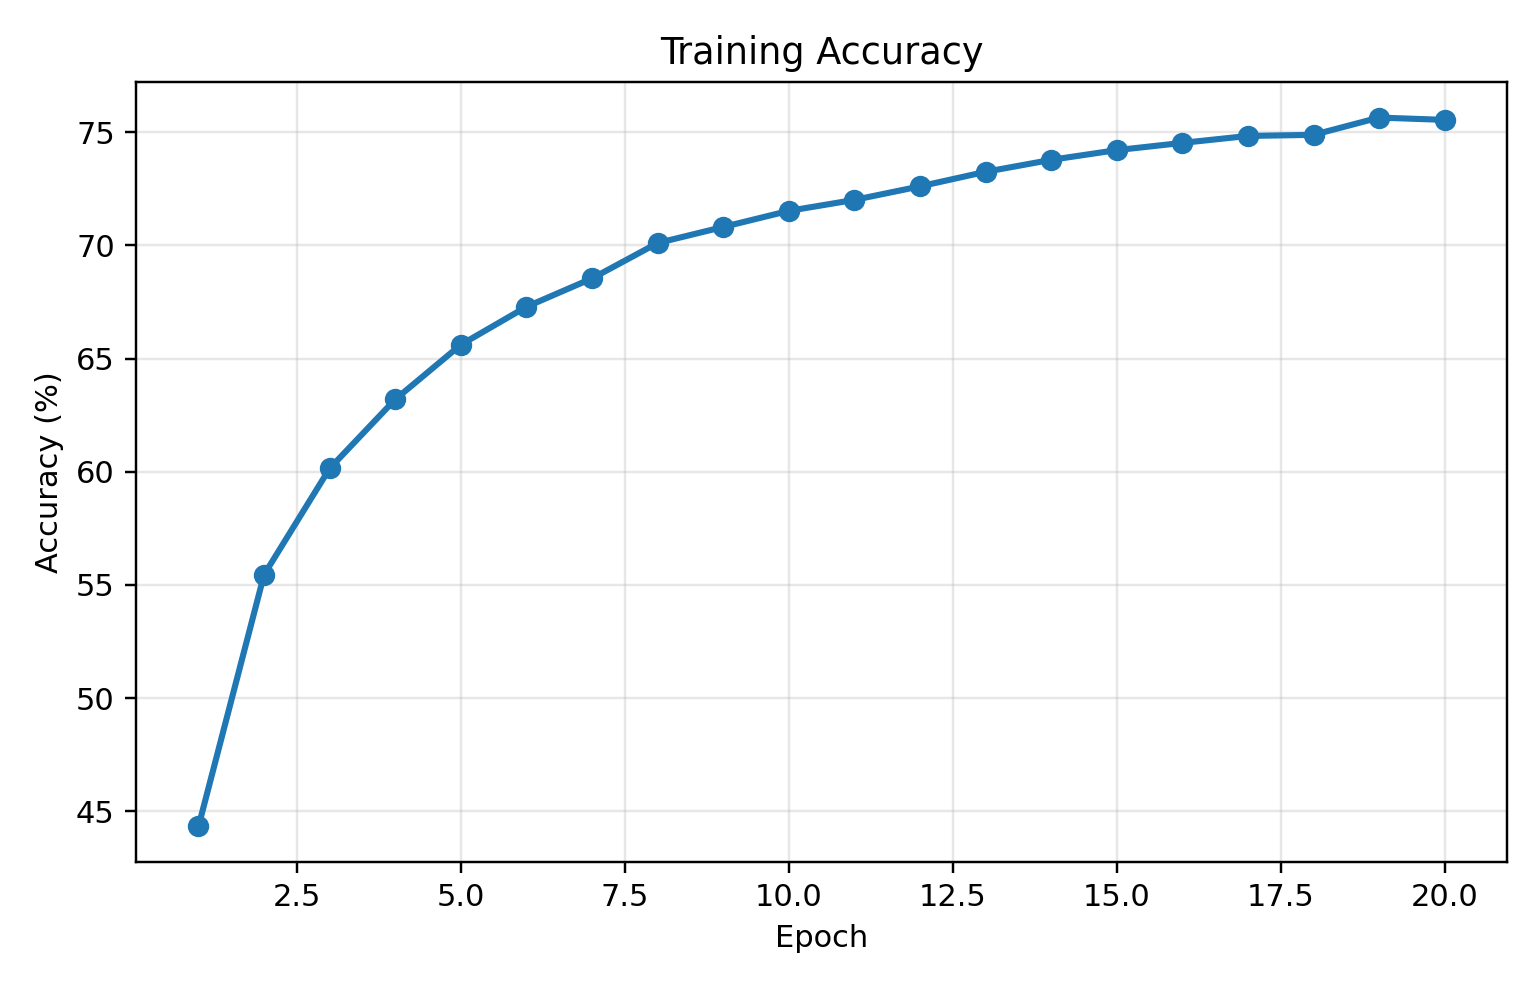


 training_loss.png


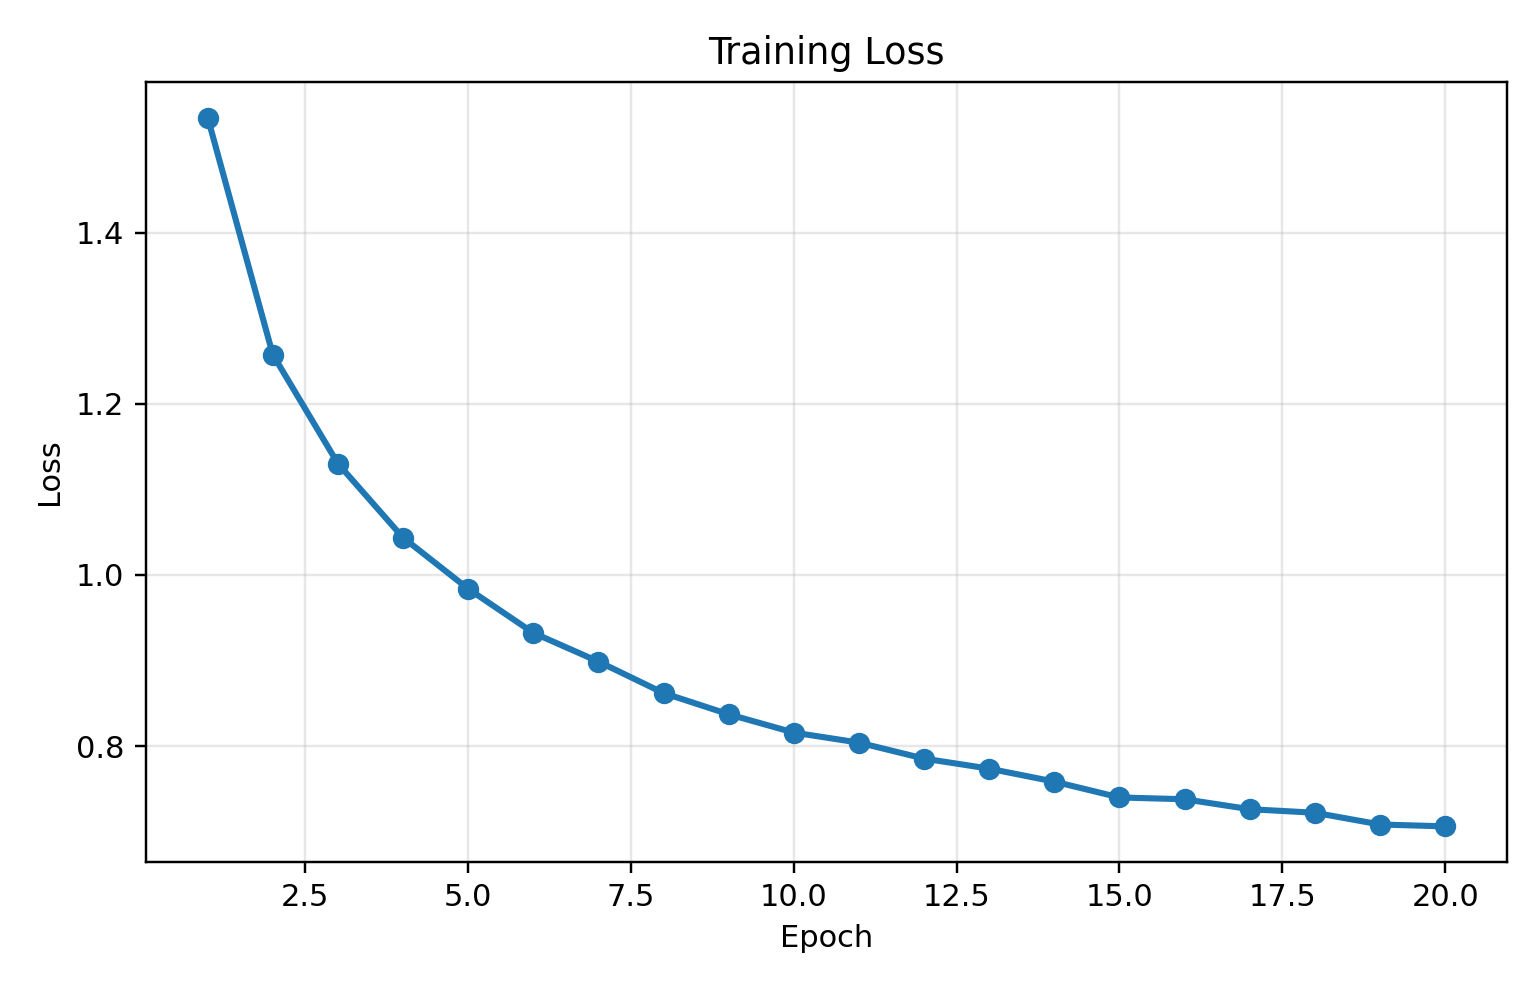


 validation_accuracy.png


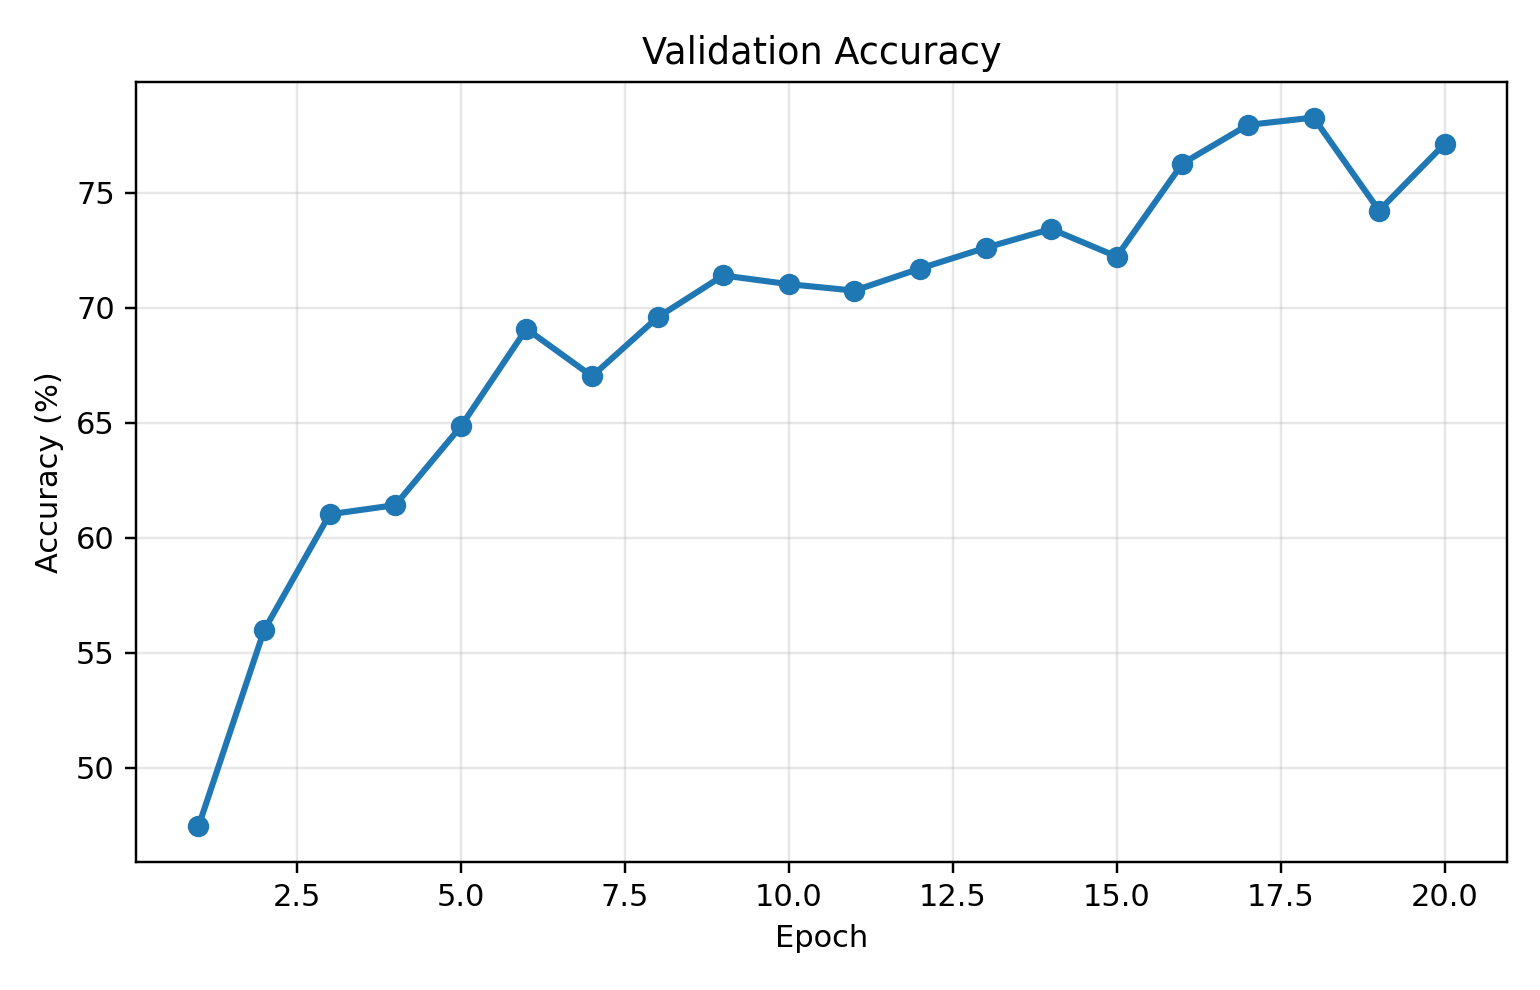


 validation_loss.png


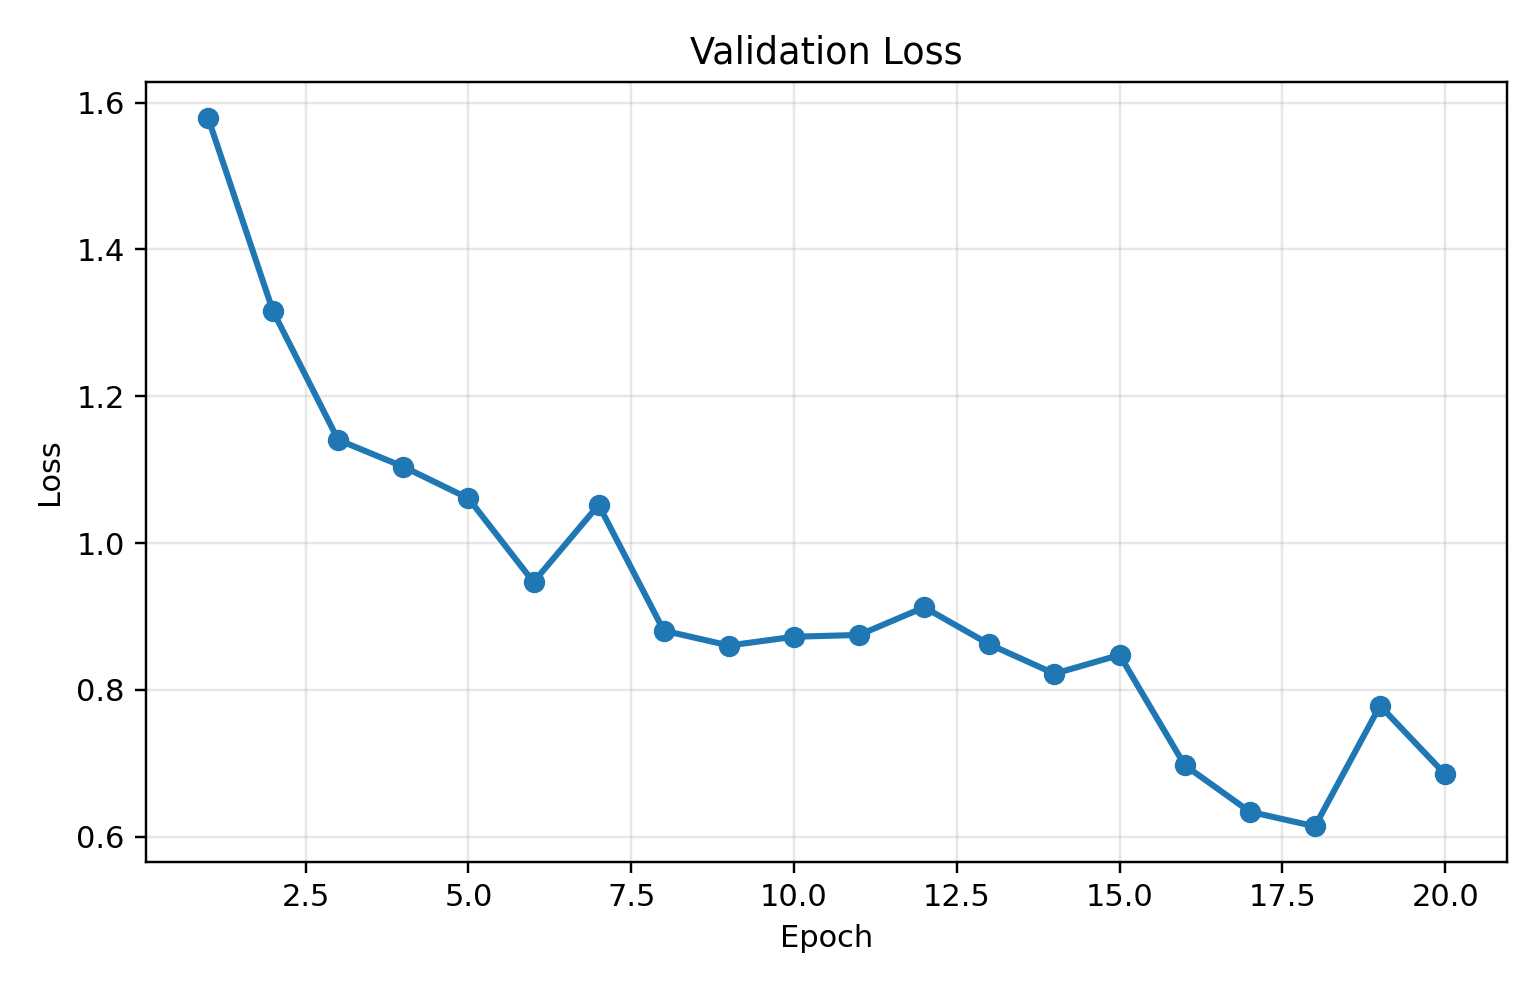

In [27]:
from IPython.display import Image, display

plot_files = [
    "training_accuracy.png",
    "training_loss.png",
    "validation_accuracy.png",
    "validation_loss.png",
]

for plot_file in plot_files:

    print("\n", plot_file)

    display(
        Image(
            filename=f"outputs/plots/{plot_file}"
        )
    )

In [28]:
import pandas as pd

baseline_history = pd.read_csv(
    "outputs/baseline_history.csv"
)

baseline_history

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,1,1.534261,44.340000,1.579571,47.46
1,2,1.257427,55.455556,1.315683,55.98
2,3,1.130066,60.146667,1.140558,61.02
3,4,1.043616,63.195556,1.104015,61.42
4,5,0.983843,65.608889,1.060901,64.84
5,6,0.932378,67.284444,0.946847,69.08
6,7,0.898840,68.537778,1.051973,67.02
7,8,0.862065,70.100000,0.880739,69.58
8,9,0.837279,70.808889,0.860442,71.40
9,10,0.815896,71.520000,0.872382,71.02


In [29]:
%cd /content/vgg6_workspace/VGG6-CIFAR10

/content/vgg6_workspace/VGG6-CIFAR10


In [30]:
#Optimizer Sweep
from pathlib import Path

required_files = [
    "configs/activation_sweep.yaml",
    "configs/optimizer_sweep.yaml",
    "configs/combined_sweep.yaml",
    "configs/best.yaml",
    "scripts/run_sweep.py",
    "scripts/show_best_run.py",
    "scripts/export_sweep_plots.py",
]

for file in required_files:
    print(
        f"{file:40}",
        "FOUND" if Path(file).exists() else "MISSING"
    )

configs/activation_sweep.yaml            FOUND
configs/optimizer_sweep.yaml             FOUND
configs/combined_sweep.yaml              FOUND
configs/best.yaml                        FOUND
scripts/run_sweep.py                     FOUND
scripts/show_best_run.py                 FOUND
scripts/export_sweep_plots.py            FOUND


In [31]:
!pip install -q wandb

In [32]:
#W&B Authentication
import getpass
import wandb

wandb.login(
    key=getpass.getpass("Enter your W&B API key: ")
)

print("W&B login completed.")

Enter your W&B API key: ··········


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login completed.


In [34]:
#Activation Sweep
from pathlib import Path

print(
    Path("configs/activation_sweep.yaml").read_text()
)

program: scripts/run_sweep.py
method: grid
metric:
  name: best_validation_accuracy
  goal: maximize
parameters:
  activation: {values: [relu, sigmoid, tanh, silu, gelu]}
  optimizer: {value: adam}
  learning_rate: {value: 0.001}
  batch_size: {value: 64}
  epochs: {value: 20}
  weight_decay: {value: 0.0005}
  seed: {value: 42}
  workers: {value: 2}
  data_dir: {value: data}



In [35]:
!wandb sweep configs/activation_sweep.yaml

wandb: Creating sweep from: configs/activation_sweep.yaml
wandb: Creating sweep with ID: eq18u0hc
wandb: View sweep at: https://wandb.ai/cs25m537-indian-institute-of-technology-madras/uncategorized/sweeps/eq18u0hc
wandb: Run sweep agent with: wandb agent cs25m537-indian-institute-of-technology-madras/uncategorized/eq18u0hc


In [36]:
ACTIVATION_SWEEP = "cs25m537-indian-institute-of-technology-madras/uncategorized/eq18u0hc"

print("Activation sweep:", ACTIVATION_SWEEP)

Activation sweep: cs25m537-indian-institute-of-technology-madras/uncategorized/eq18u0hc


In [37]:
#Result Extraction
!wandb agent --count 5 $ACTIVATION_SWEEP

wandb: Starting wandb agent 🕵️
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
2026-10-30 05:27:13,091 - wandb.wandb_agent - INFO - Running runs: []
2026-10-30 05:27:13,653 - wandb.wandb_agent - INFO - Agent received command: run
2026-10-30 05:27:13,653 - wandb.wandb_agent - INFO - Agent starting run with config:
	activation: relu
	batch_size: 64
	data_dir: data
	epochs: 20
	learning_rate: 0.001
	optimizer: adam
	seed: 42
	weight_decay: 0.0005
	workers: 2
2026-10-30 05:27:13,655 - wandb.wandb_agent - INFO - About to run command: /usr/bin/env python scripts/run_sweep.py --activation=relu --batch_size=64 --data_dir=data --epochs=20 --learning_rate=0.001 --optimizer=adam --seed=42 --weight_decay=0.0005 --workers=2
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relo

In [38]:
#Result Extraction
print(
    Path("configs/optimizer_sweep.yaml").read_text()
)

program: scripts/run_sweep.py
method: grid
metric:
  name: best_validation_accuracy
  goal: maximize
parameters:
  activation: {value: relu}
  optimizer: {values: [sgd, nesterov_sgd, adam, adagrad, rmsprop, nadam]}
  learning_rate: {value: 0.001}
  batch_size: {value: 64}
  epochs: {value: 20}
  weight_decay: {value: 0.0005}
  seed: {value: 42}
  workers: {value: 2}
  data_dir: {value: data}



In [39]:
!wandb sweep configs/optimizer_sweep.yaml

wandb: Creating sweep from: configs/optimizer_sweep.yaml
wandb: Creating sweep with ID: w5nl04g1
wandb: View sweep at: https://wandb.ai/cs25m537-indian-institute-of-technology-madras/uncategorized/sweeps/w5nl04g1
wandb: Run sweep agent with: wandb agent cs25m537-indian-institute-of-technology-madras/uncategorized/w5nl04g1


In [40]:
OPTIMIZER_SWEEP = "cs25m537-indian-institute-of-technology-madras/uncategorized/w5nl04g1"

print("Optimizer sweep:", OPTIMIZER_SWEEP)

Optimizer sweep: cs25m537-indian-institute-of-technology-madras/uncategorized/w5nl04g1


In [41]:
!wandb agent --count 6 $OPTIMIZER_SWEEP

wandb: Starting wandb agent 🕵️
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
2026-10-30 05:48:44,307 - wandb.wandb_agent - INFO - Running runs: []
2026-10-30 05:48:44,837 - wandb.wandb_agent - INFO - Agent received command: run
2026-10-30 05:48:44,838 - wandb.wandb_agent - INFO - Agent starting run with config:
	activation: relu
	batch_size: 64
	data_dir: data
	epochs: 20
	learning_rate: 0.001
	optimizer: sgd
	seed: 42
	weight_decay: 0.0005
	workers: 2
2026-10-30 05:48:44,839 - wandb.wandb_agent - INFO - About to run command: /usr/bin/env python scripts/run_sweep.py --activation=relu --batch_size=64 --data_dir=data --epochs=20 --learning_rate=0.001 --optimizer=sgd --seed=42 --weight_decay=0.0005 --workers=2
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogi

In [42]:
print(
    Path("configs/combined_sweep.yaml").read_text()
)

program: scripts/run_sweep.py
method: random
metric:
  name: best_validation_accuracy
  goal: maximize
parameters:
  activation: {values: [relu, silu, gelu]}
  optimizer: {values: [adam, nadam, rmsprop]}
  learning_rate: {values: [0.0001, 0.0005, 0.001, 0.005]}
  batch_size: {values: [32, 64, 128]}
  epochs: {values: [10, 20, 30]}
  weight_decay: {value: 0.0005}
  seed: {value: 42}
  workers: {value: 2}
  data_dir: {value: data}



In [43]:
!wandb sweep configs/combined_sweep.yaml

wandb: Creating sweep from: configs/combined_sweep.yaml
wandb: Creating sweep with ID: x5eic8a8
wandb: View sweep at: https://wandb.ai/cs25m537-indian-institute-of-technology-madras/uncategorized/sweeps/x5eic8a8
wandb: Run sweep agent with: wandb agent cs25m537-indian-institute-of-technology-madras/uncategorized/x5eic8a8


In [44]:
COMBINED_SWEEP = "cs25m537-indian-institute-of-technology-madras/uncategorized/x5eic8a8"

print("Combined sweep:", COMBINED_SWEEP)

Combined sweep: cs25m537-indian-institute-of-technology-madras/uncategorized/x5eic8a8


In [45]:
!wandb agent --count 15 $COMBINED_SWEEP

wandb: Starting wandb agent 🕵️
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
2026-10-30 06:14:37,904 - wandb.wandb_agent - INFO - Running runs: []
2026-10-30 06:14:38,626 - wandb.wandb_agent - INFO - Agent received command: run
2026-10-30 06:14:38,626 - wandb.wandb_agent - INFO - Agent starting run with config:
	activation: relu
	batch_size: 64
	data_dir: data
	epochs: 10
	learning_rate: 0.0001
	optimizer: nadam
	seed: 42
	weight_decay: 0.0005
	workers: 2
2026-10-30 06:14:38,627 - wandb.wandb_agent - INFO - About to run command: /usr/bin/env python scripts/run_sweep.py --activation=relu --batch_size=64 --data_dir=data --epochs=10 --learning_rate=0.0001 --optimizer=nadam --seed=42 --weight_decay=0.0005 --workers=2
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force 

In [46]:
from pathlib import Path

history_files = sorted(
    Path("outputs").glob("history_*.csv")
)

checkpoint_files = sorted(
    Path("checkpoints").glob("sweep_*.pt")
)

print("History files:")
for file in history_files:
    print(file)

print("\nSweep checkpoints:")
for file in checkpoint_files:
    print(file)

History files:
outputs/history_0cwc8x71.csv
outputs/history_0my6upgz.csv
outputs/history_3epqaw4z.csv
outputs/history_3yxs53tj.csv
outputs/history_481hvdb1.csv
outputs/history_52j8uvnf.csv
outputs/history_5fxmk2kb.csv
outputs/history_7l8acbtg.csv
outputs/history_9751jm6n.csv
outputs/history_ag8m345l.csv
outputs/history_d6ygcv6u.csv
outputs/history_drxrldi3.csv
outputs/history_f0m4asbd.csv
outputs/history_gfffg43m.csv
outputs/history_gth7astr.csv
outputs/history_jb0ol5hd.csv
outputs/history_kb2dj0ev.csv
outputs/history_mhaxy0z3.csv
outputs/history_mlovhkzg.csv
outputs/history_nuwq1wsg.csv
outputs/history_p183an5j.csv
outputs/history_u7c1e3x8.csv
outputs/history_w4m78atj.csv
outputs/history_wa2jsf4v.csv
outputs/history_wwtwqgup.csv
outputs/history_ytsn7wlo.csv

Sweep checkpoints:
checkpoints/sweep_0cwc8x71.pt
checkpoints/sweep_0my6upgz.pt
checkpoints/sweep_3epqaw4z.pt
checkpoints/sweep_3yxs53tj.pt
checkpoints/sweep_481hvdb1.pt
checkpoints/sweep_52j8uvnf.pt
checkpoints/sweep_5fxmk2kb.pt
c

In [47]:
!python scripts/export_sweep_plots.py \
    --sweep $COMBINED_SWEEP \
    --output-dir outputs/sweep_plots

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
Saved six plots and sweep_summary.csv to outputs/sweep_plots


In [48]:
from pathlib import Path

plot_dir = Path("outputs/sweep_plots")

required_plots = [
    "parallel_coordinates.png",
    "validation_accuracy_vs_step_scatter.png",
    "training_accuracy_all_runs.png",
    "training_loss_all_runs.png",
    "validation_accuracy_all_runs.png",
    "validation_loss_all_runs.png",
]

all_plots_available = True

for plot in required_plots:

    path = plot_dir / plot

    status = "FOUND" if path.exists() else "MISSING"

    print(
        f"{plot:48} {status}"
    )

    if not path.exists():
        all_plots_available = False

print()

if all_plots_available:
    print("SUCCESS: All six required plots generated.")
else:
    print("ERROR: One or more required plots are missing.")

parallel_coordinates.png                         FOUND
validation_accuracy_vs_step_scatter.png          FOUND
training_accuracy_all_runs.png                   FOUND
training_loss_all_runs.png                       FOUND
validation_accuracy_all_runs.png                 FOUND
validation_loss_all_runs.png                     FOUND

SUCCESS: All six required plots generated.



parallel_coordinates.png


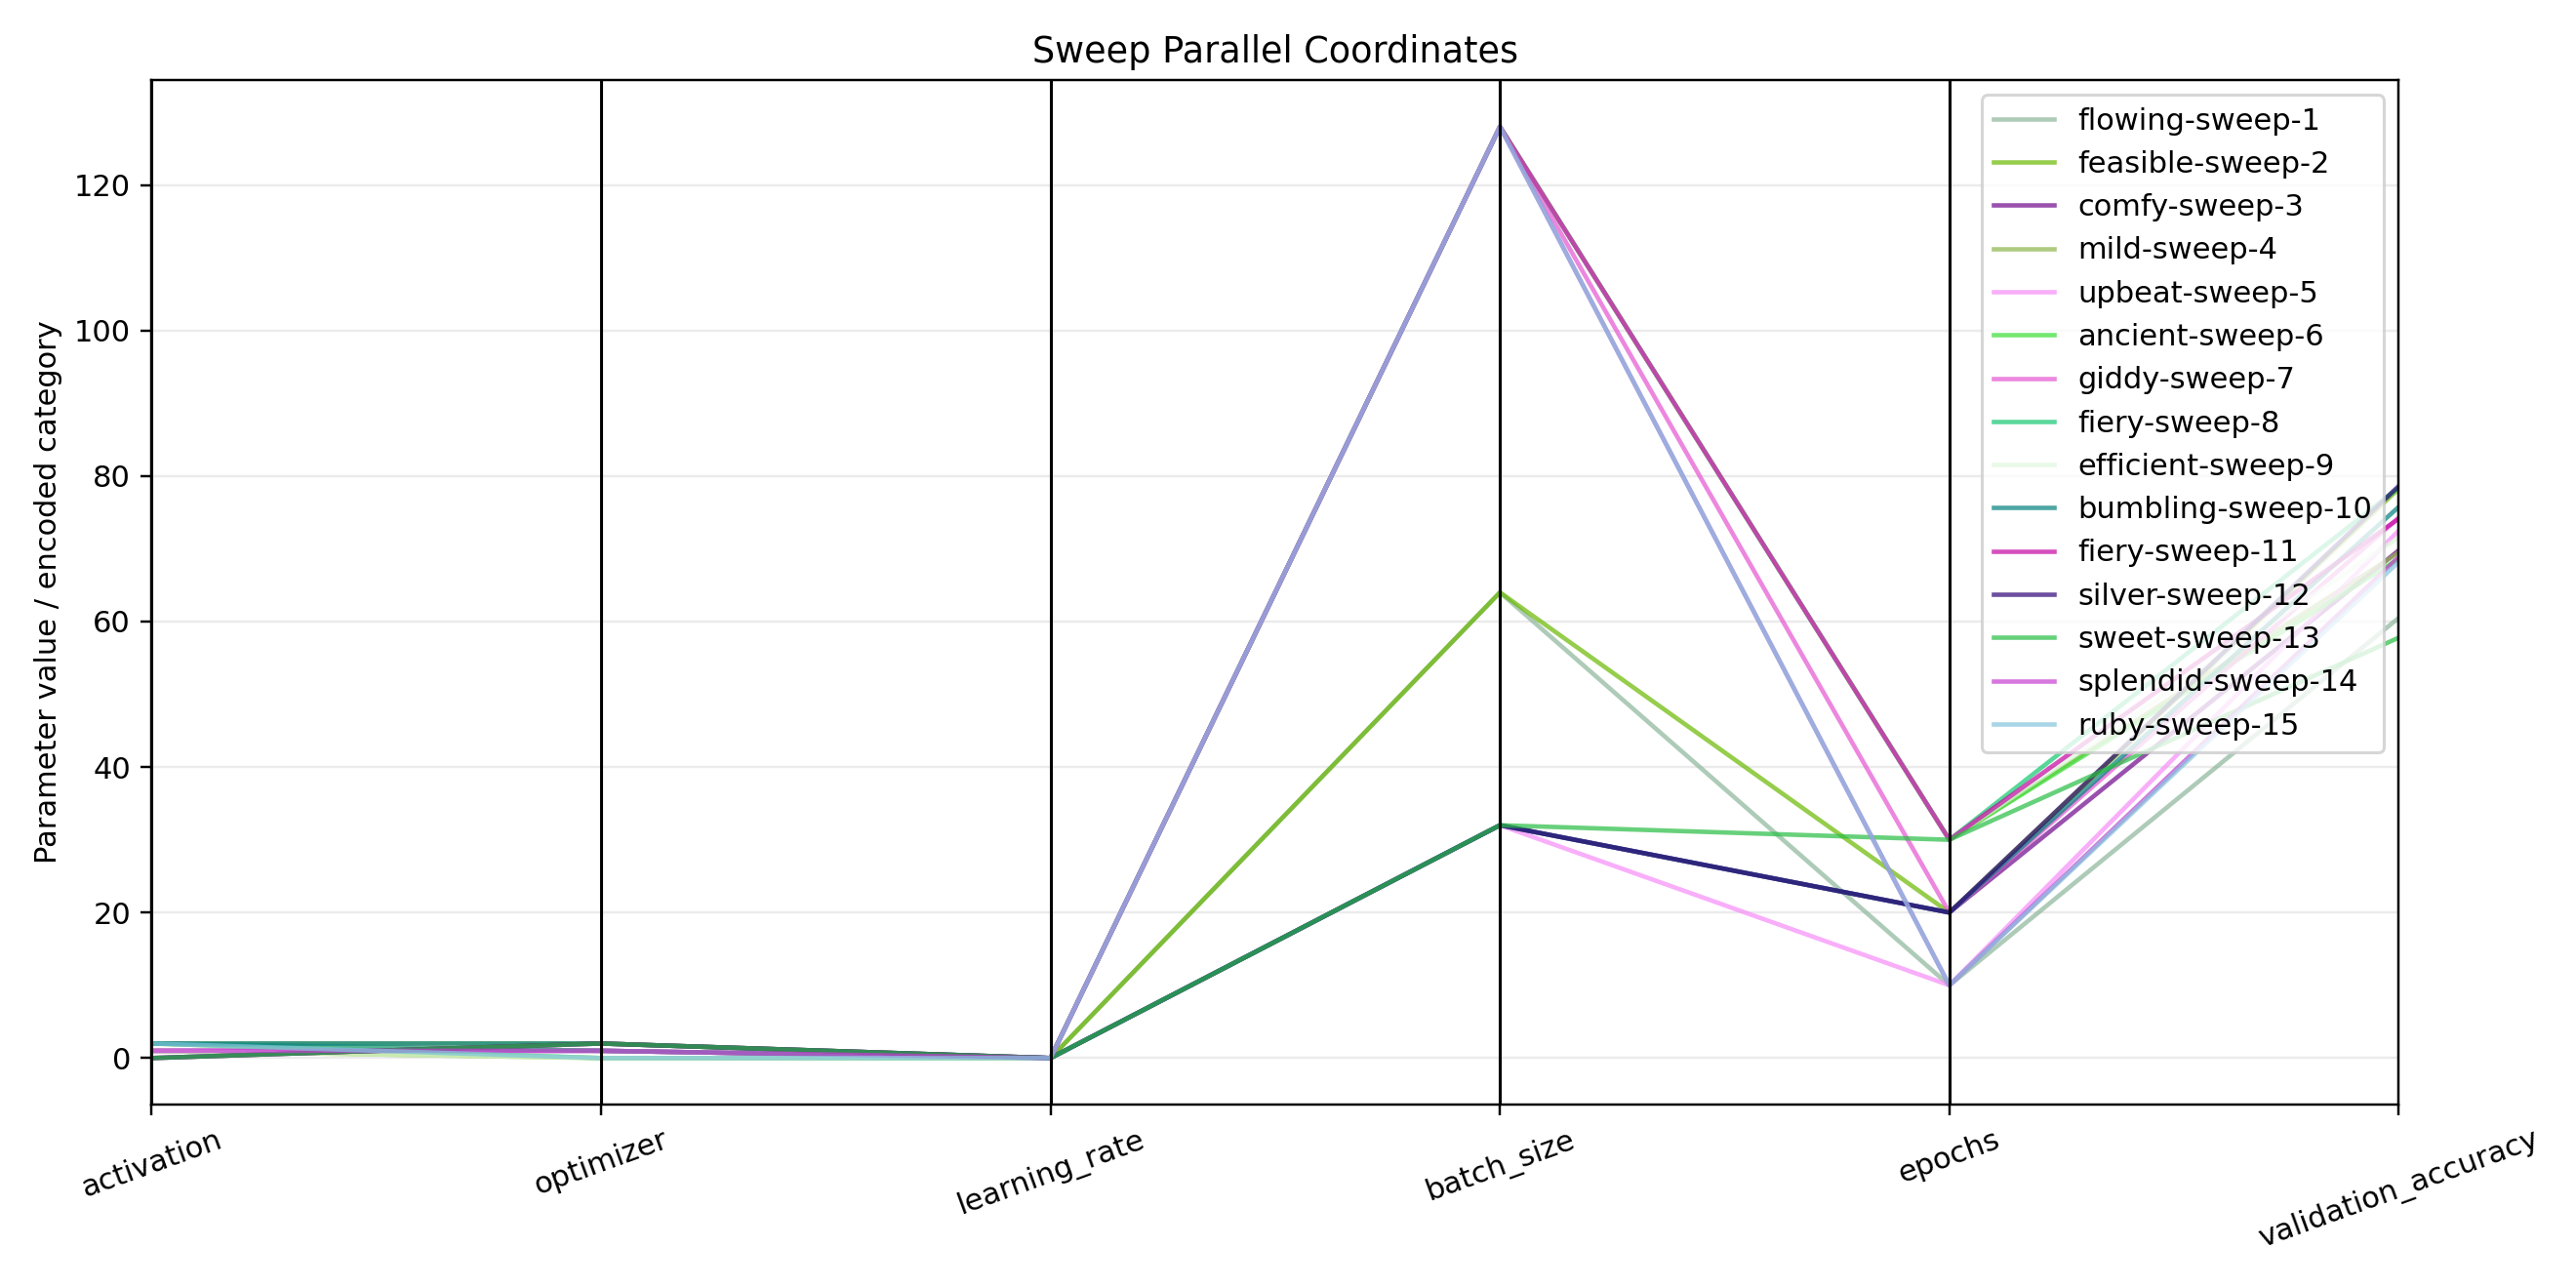


validation_accuracy_vs_step_scatter.png


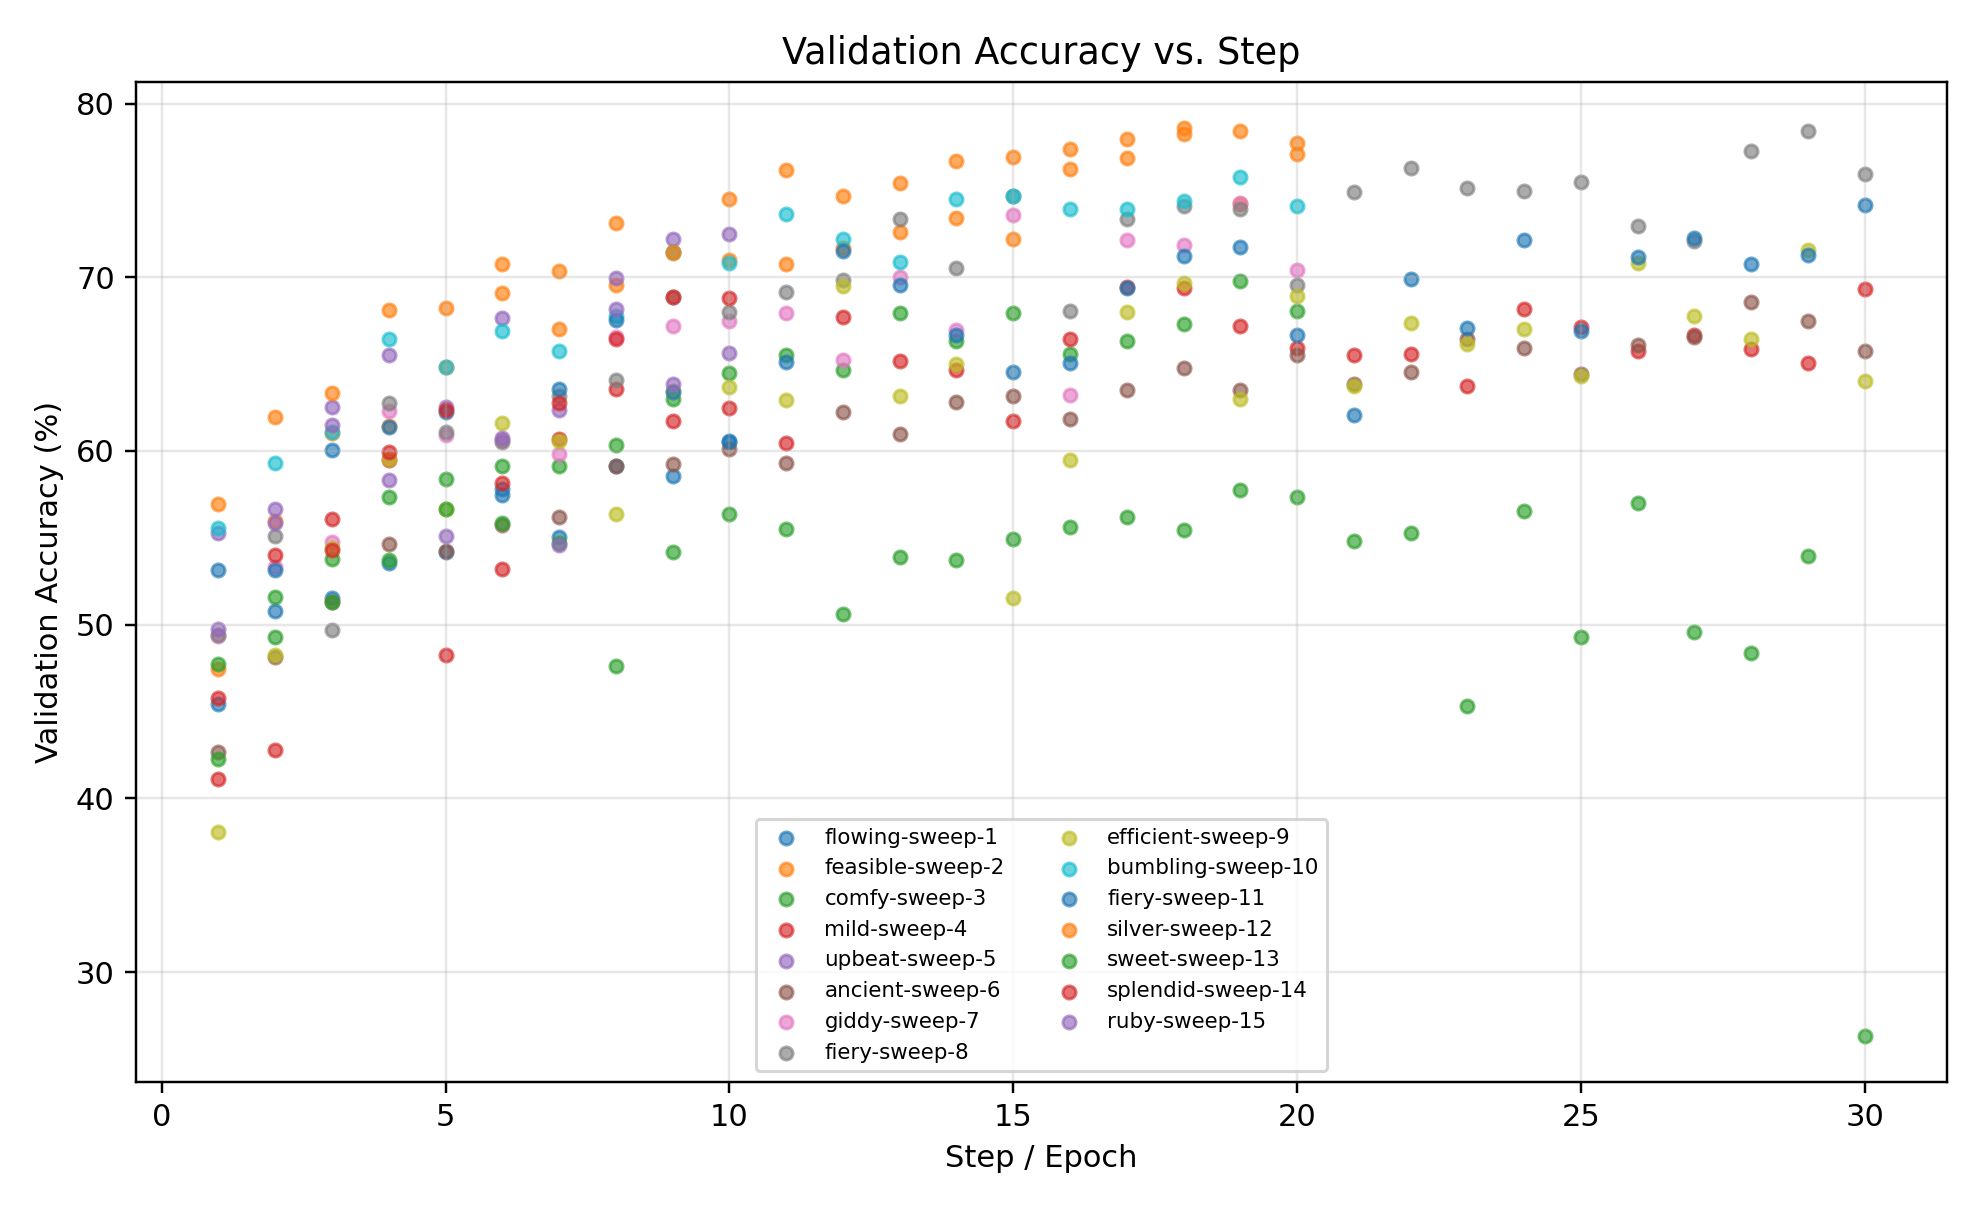


training_accuracy_all_runs.png


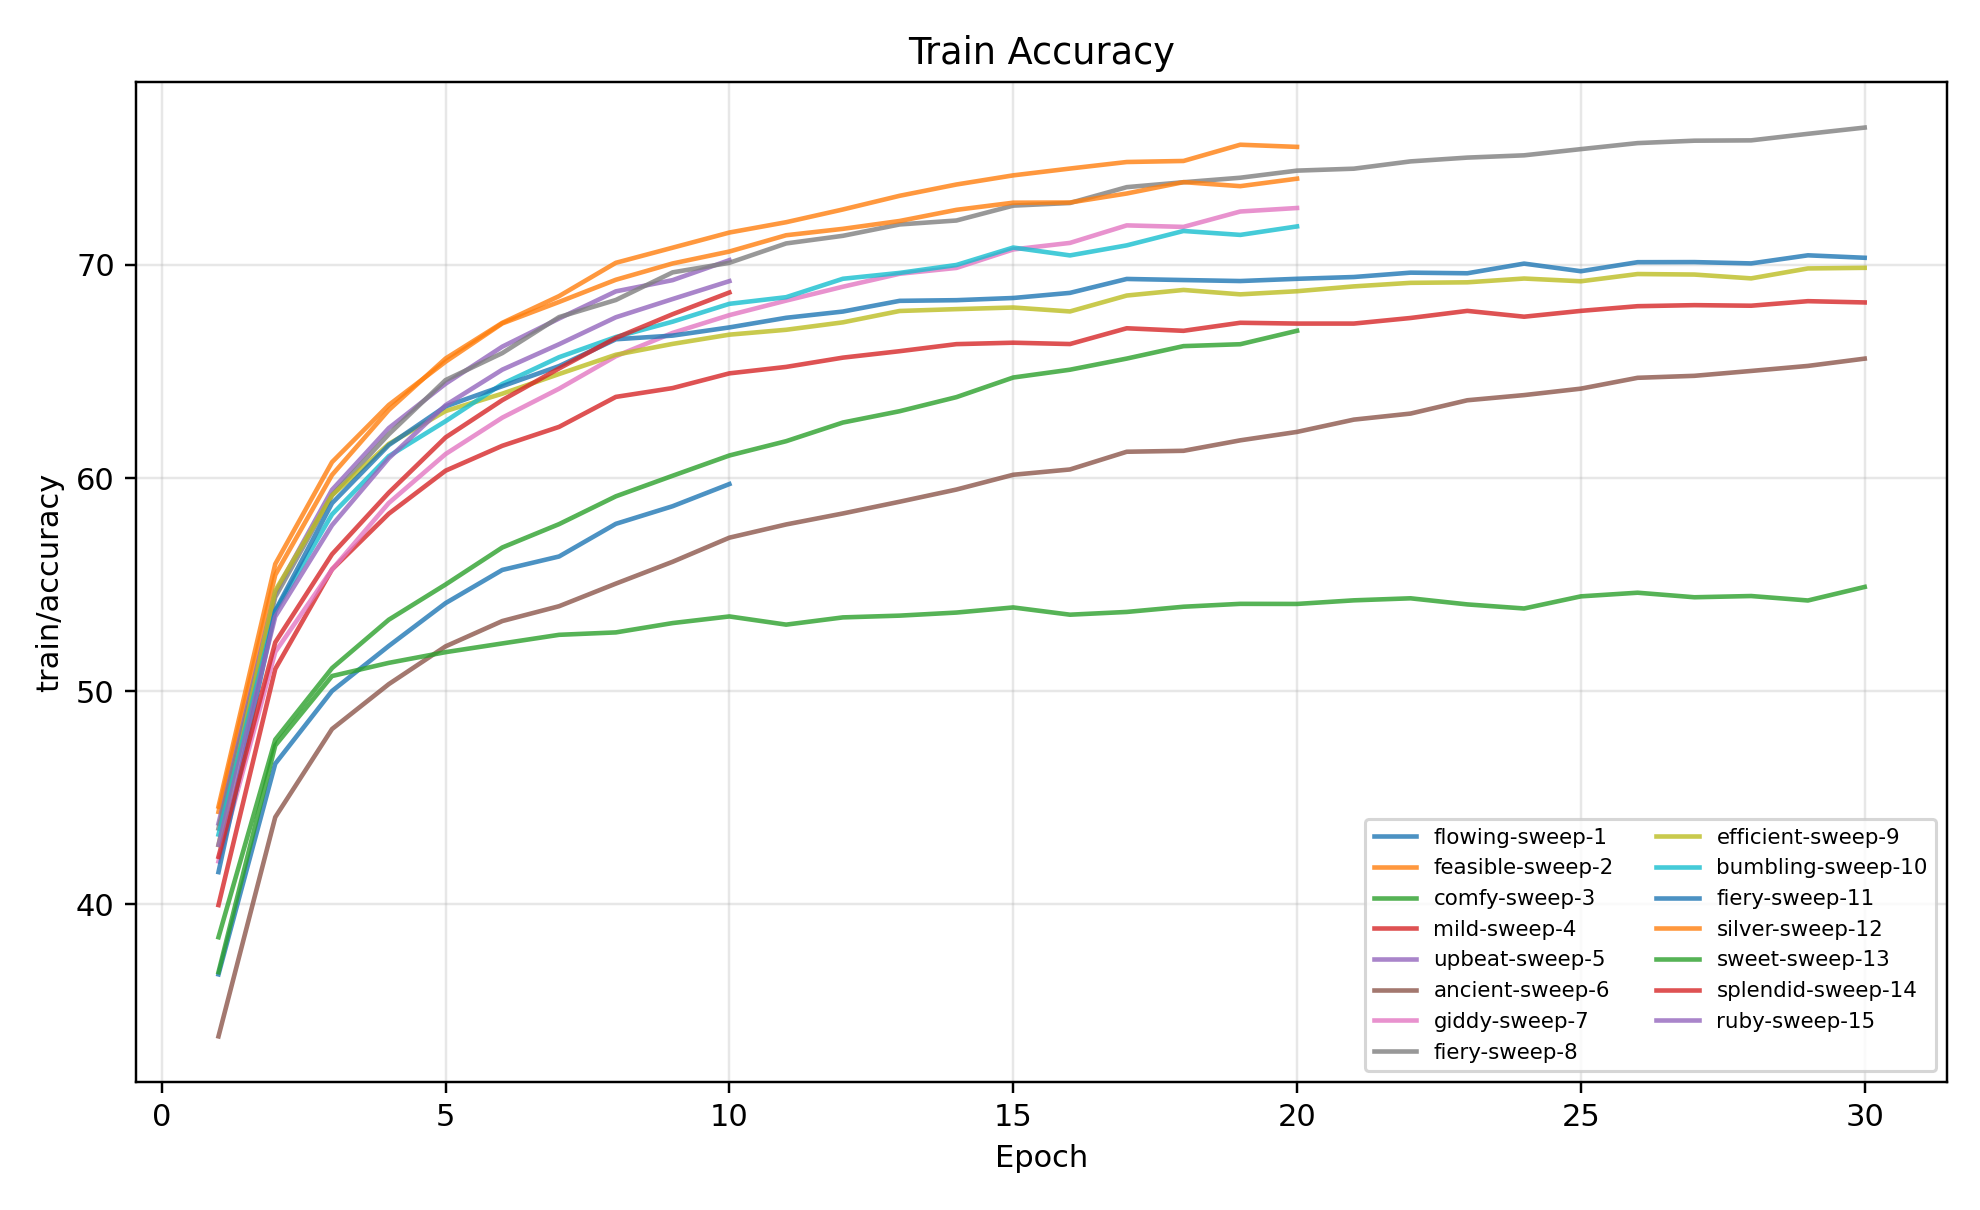


training_loss_all_runs.png


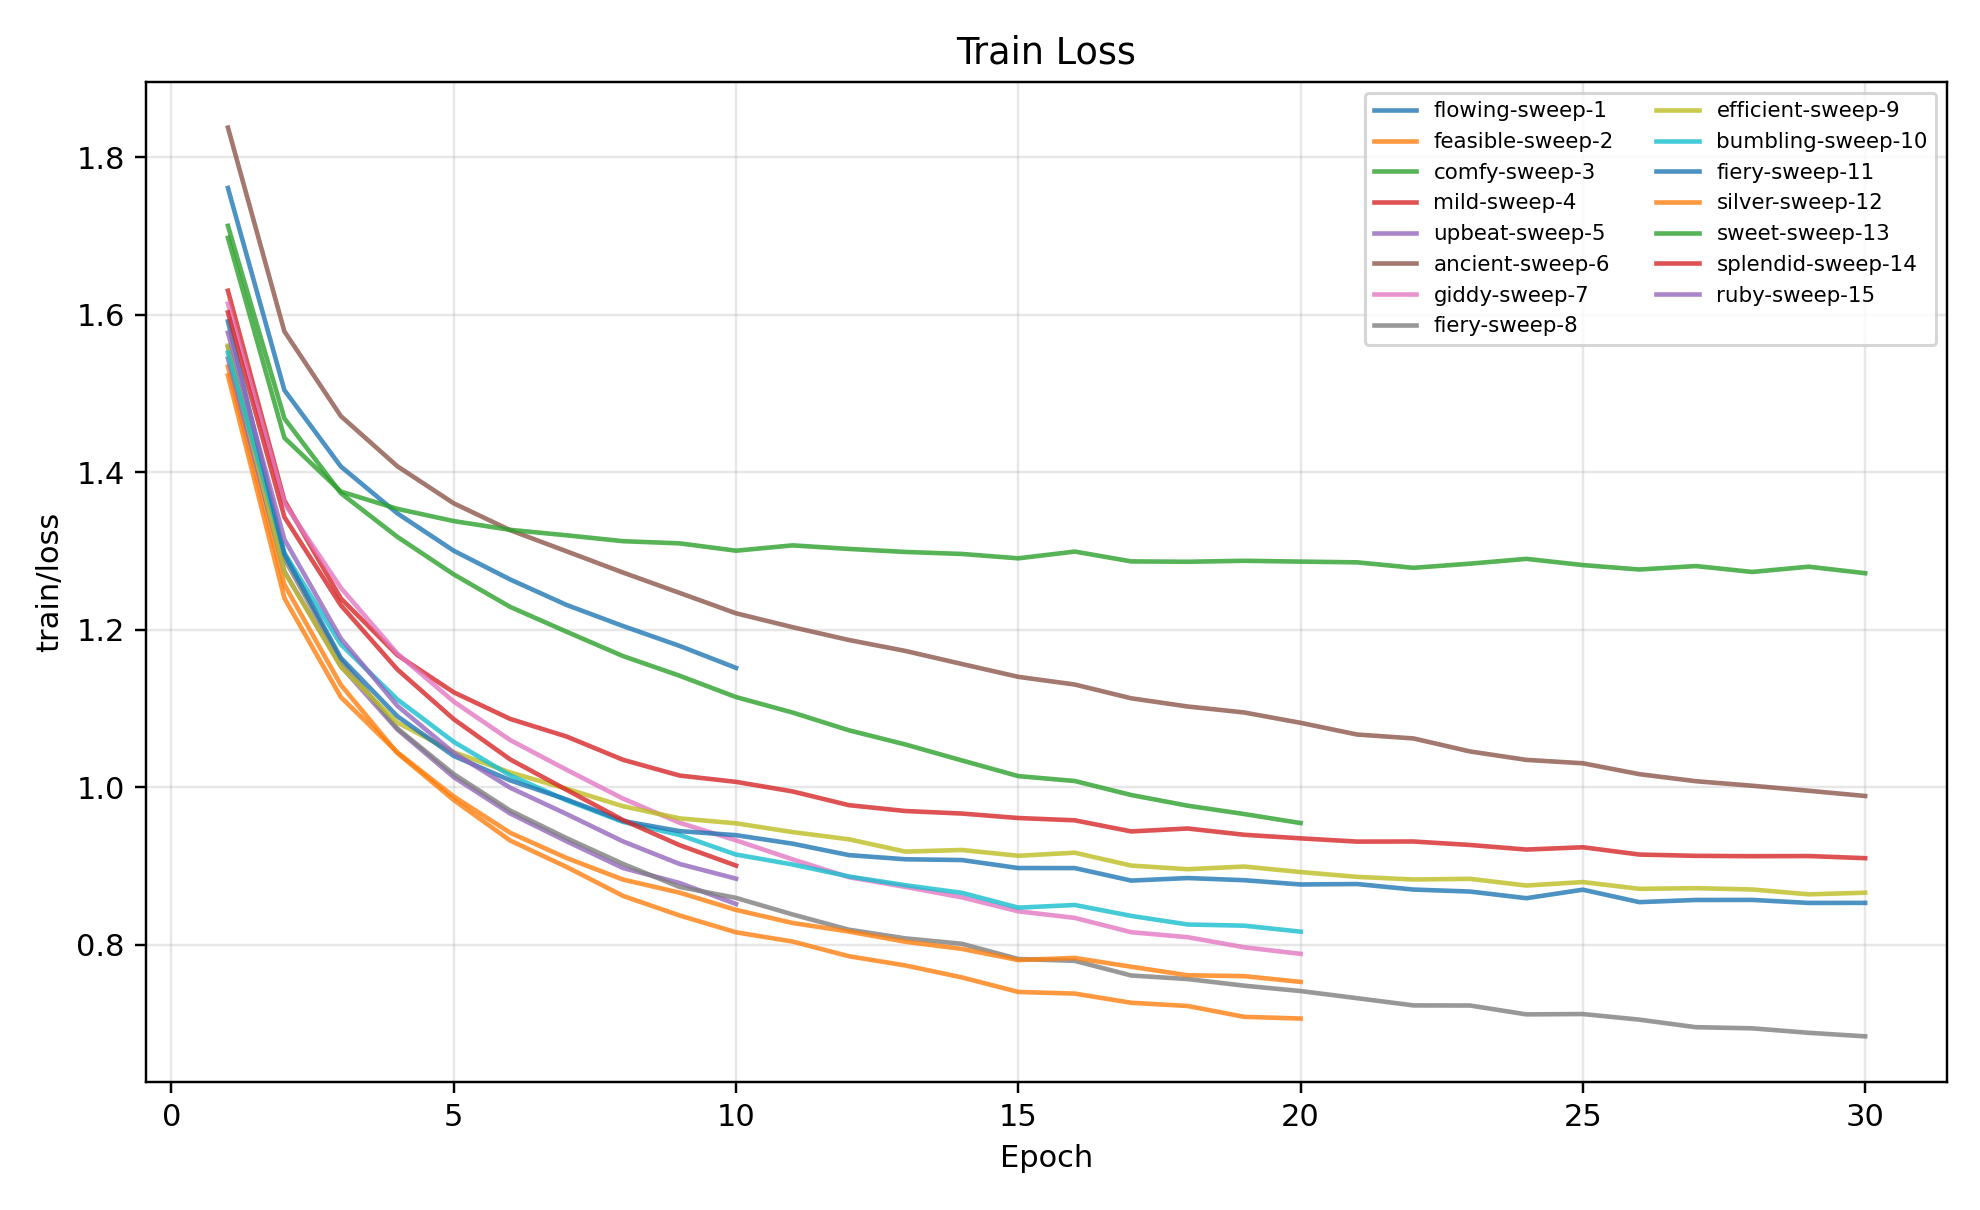


validation_accuracy_all_runs.png


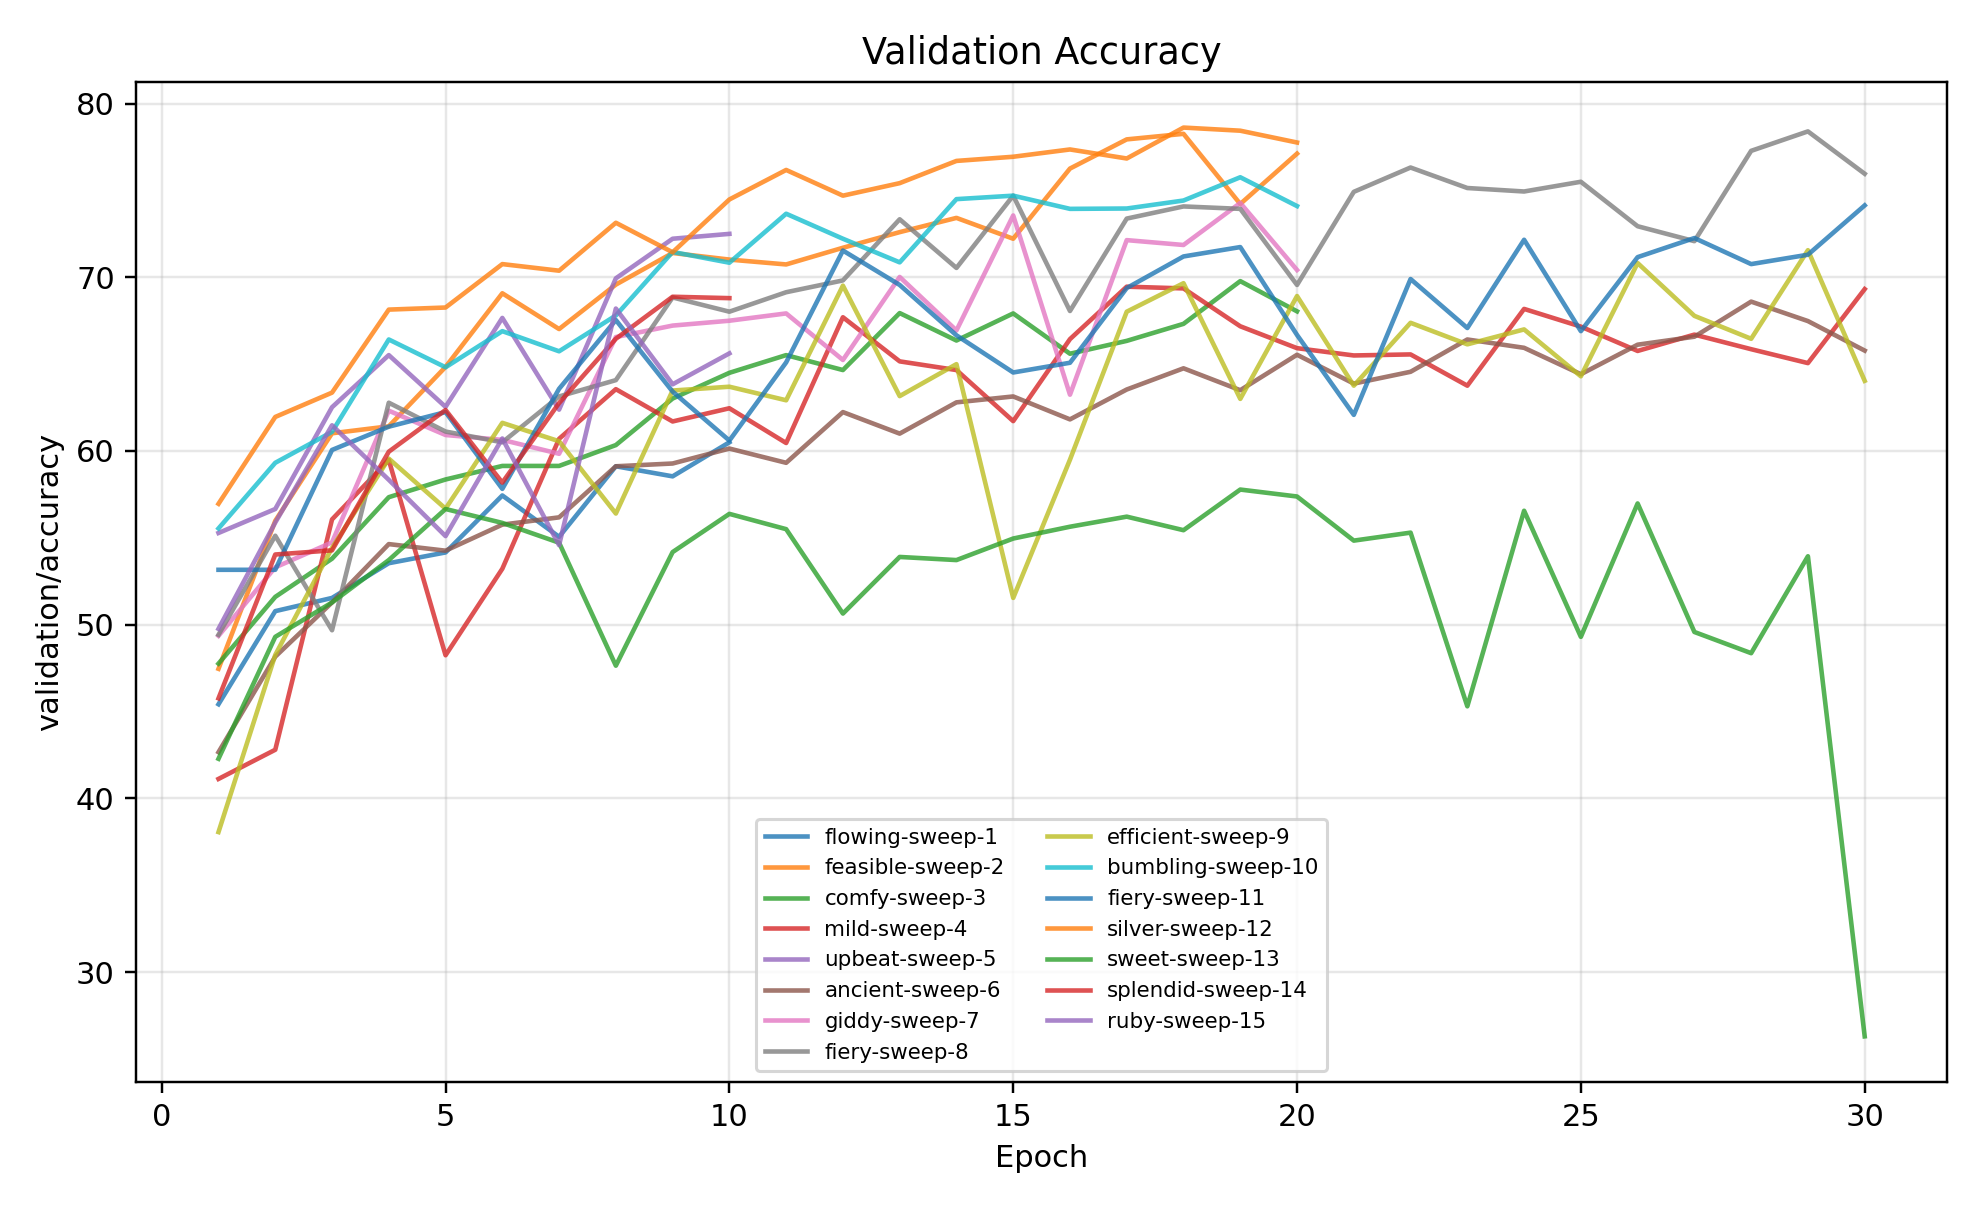


validation_loss_all_runs.png


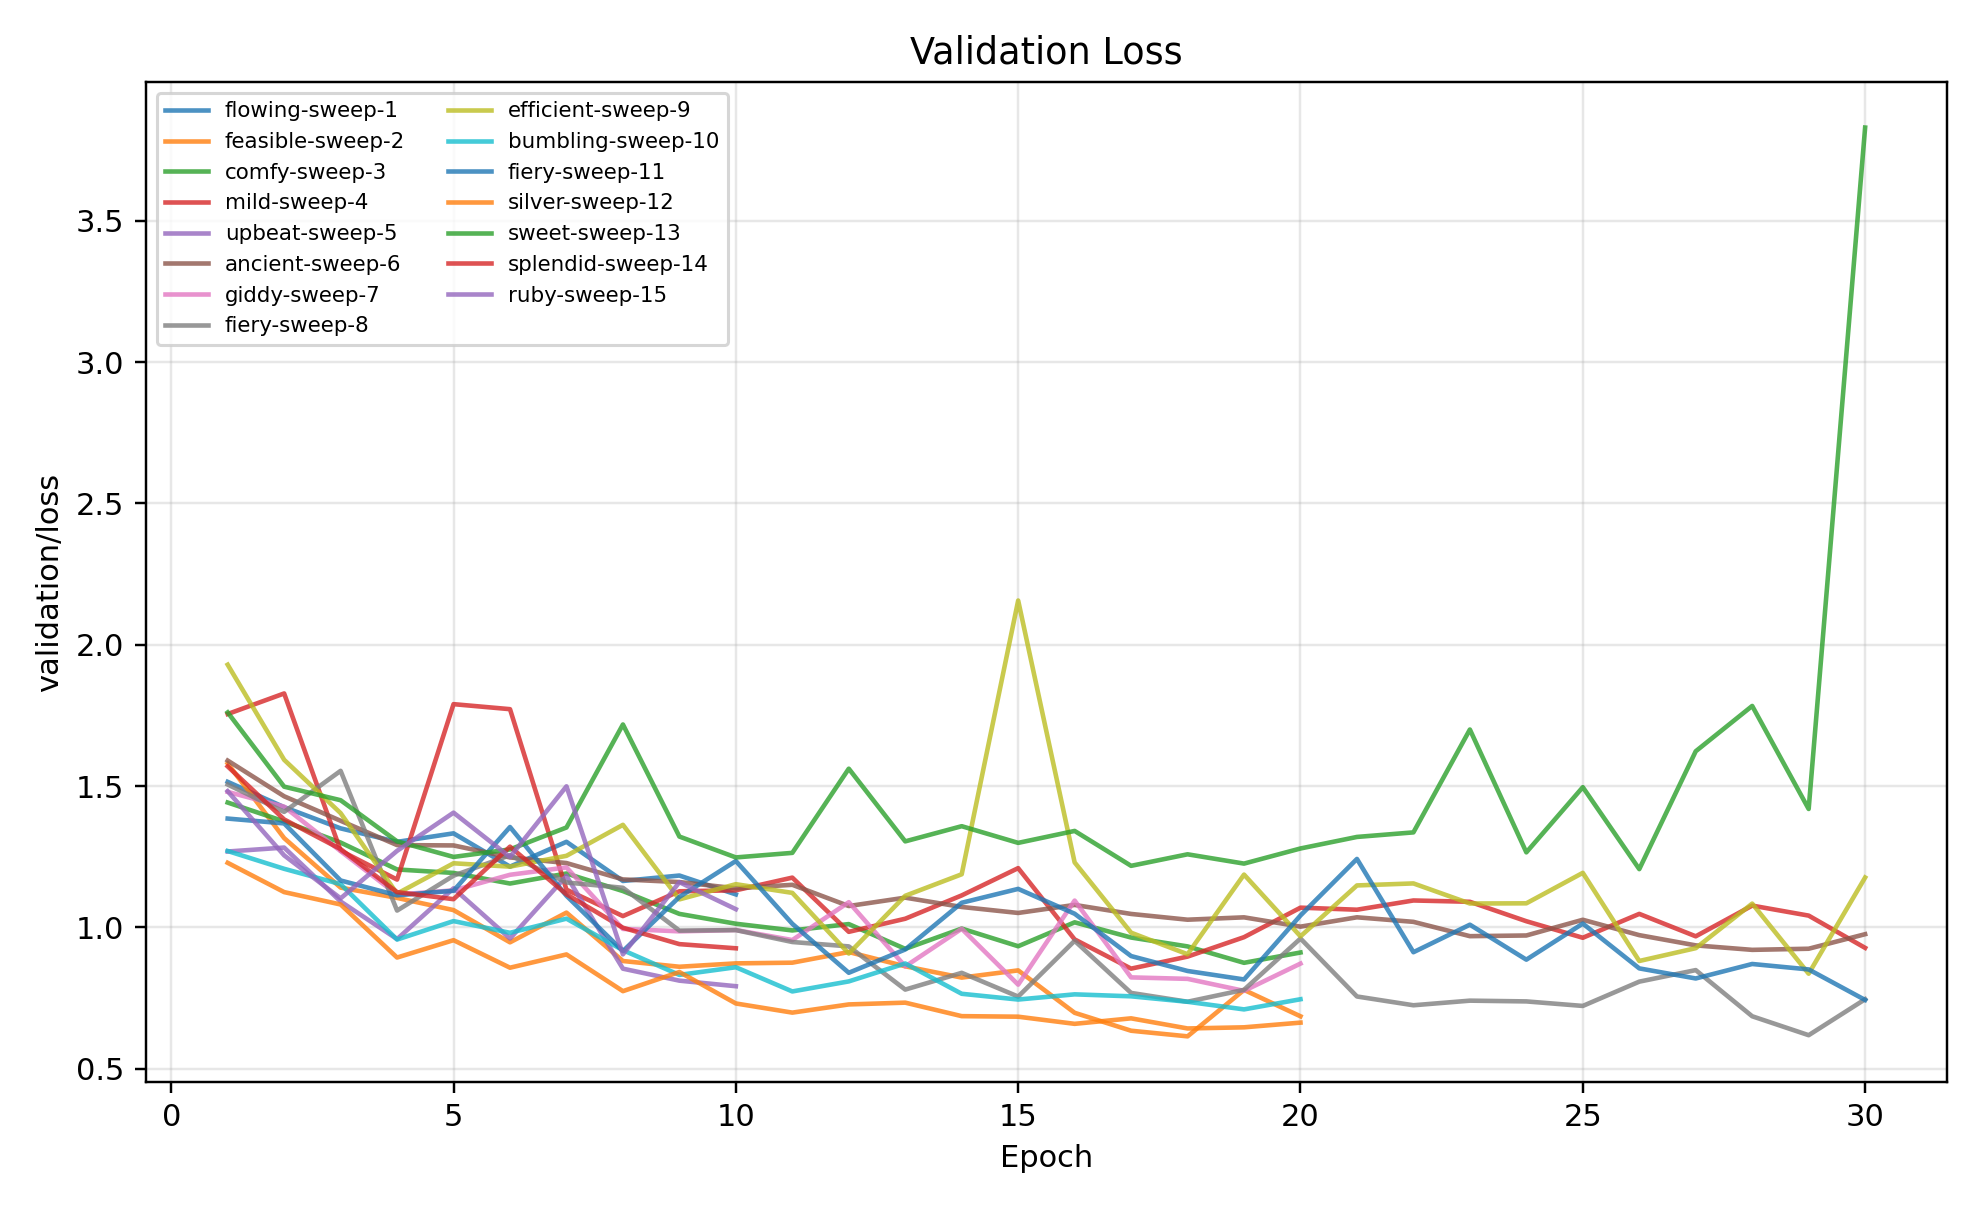

In [49]:
from IPython.display import Image, display

for plot in required_plots:

    print("\n" + "=" * 70)
    print(plot)
    print("=" * 70)

    display(
        Image(
            filename=f"outputs/sweep_plots/{plot}"
        )
    )

In [50]:
import pandas as pd

results = pd.read_csv(
    "outputs/sweep_plots/sweep_summary.csv"
)

print(
    results.to_string(index=False)
)

              run activation optimizer  learning_rate  batch_size  epochs  validation_accuracy
  flowing-sweep-1       relu     nadam         0.0001          64      10                60.50
 feasible-sweep-2       relu      adam         0.0010          64      20                78.26
    comfy-sweep-3       relu     nadam         0.0001          32      20                69.78
     mild-sweep-4       silu   rmsprop         0.0005         128      30                69.46
   upbeat-sweep-5       relu     nadam         0.0005          32      10                72.50
  ancient-sweep-6       silu      adam         0.0001         128      30                68.60
    giddy-sweep-7       silu     nadam         0.0005         128      20                74.28
    fiery-sweep-8       silu     nadam         0.0010         128      30                78.40
efficient-sweep-9       relu      adam         0.0050         128      30                71.56
bumbling-sweep-10       silu   rmsprop         0.0

In [51]:
results_sorted = results.sort_values(
    "validation_accuracy",
    ascending=False
).reset_index(drop=True)

print(
    results_sorted.to_string(index=False)
)

              run activation optimizer  learning_rate  batch_size  epochs  validation_accuracy
  silver-sweep-12       gelu   rmsprop         0.0001          32      20                78.62
    fiery-sweep-8       silu     nadam         0.0010         128      30                78.40
 feasible-sweep-2       relu      adam         0.0010          64      20                78.26
bumbling-sweep-10       silu   rmsprop         0.0001          32      20                75.76
    giddy-sweep-7       silu     nadam         0.0005         128      20                74.28
   fiery-sweep-11       gelu   rmsprop         0.0005         128      30                74.14
   upbeat-sweep-5       relu     nadam         0.0005          32      10                72.50
efficient-sweep-9       relu      adam         0.0050         128      30                71.56
    comfy-sweep-3       relu     nadam         0.0001          32      20                69.78
     mild-sweep-4       silu   rmsprop         0.0

In [52]:
!python scripts/show_best_run.py \
    --sweep $COMBINED_SWEEP

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
Best run: silver-sweep-12
Best validation accuracy: 78.62
Configuration:
  activation: gelu
  optimizer: rmsprop
  learning_rate: 0.0001
  batch_size: 32
  epochs: 20
  weight_decay: 0.0005
  seed: 42


In [53]:
import wandb

api = wandb.Api()

sweep = api.sweep(
    COMBINED_SWEEP
)

finished_runs = [
    run
    for run in sweep.runs
    if run.state == "finished"
    and run.summary.get(
        "best_validation_accuracy"
    ) is not None
]

if not finished_runs:
    raise RuntimeError(
        "No finished runs containing "
        "best_validation_accuracy were found."
    )

best_run = max(
    finished_runs,
    key=lambda run:
        run.summary["best_validation_accuracy"]
)

print("Best run:", best_run.name)

print(
    "Best validation accuracy:",
    best_run.summary[
        "best_validation_accuracy"
    ]
)

print("\nBest configuration:")

keys = [
    "activation",
    "optimizer",
    "learning_rate",
    "batch_size",
    "epochs",
    "weight_decay",
    "seed",
]

for key in keys:

    print(
        f"{key:20}:",
        best_run.config.get(key)
    )

Best run: silver-sweep-12
Best validation accuracy: 78.62

Best configuration:
activation          : gelu
optimizer           : rmsprop
learning_rate       : 0.0001
batch_size          : 32
epochs              : 20
weight_decay        : 0.0005
seed                : 42


In [54]:
import yaml

best_config = {
    "activation":
        best_run.config["activation"],

    "optimizer":
        best_run.config["optimizer"],

    "learning_rate":
        float(best_run.config["learning_rate"]),

    "batch_size":
        int(best_run.config["batch_size"]),

    "epochs":
        int(best_run.config["epochs"]),

    "weight_decay":
        float(
            best_run.config.get(
                "weight_decay",
                0.0005
            )
        ),

    "seed":
        int(
            best_run.config.get(
                "seed",
                42
            )
        ),

    "workers": 2,

    "data_dir": "data",

    "use_wandb": True,

    "wandb_project":
        "vgg6-cifar10",

    "checkpoint_path":
        "checkpoints/best_model.pt",

    "history_path":
        "outputs/best_history.csv",
}

with open(
    "configs/best.yaml",
    "w"
) as file:

    yaml.safe_dump(
        best_config,
        file,
        sort_keys=False
    )

print(
    "configs/best.yaml created successfully."
)

configs/best.yaml created successfully.


In [55]:
print(
    Path(
        "configs/best.yaml"
    ).read_text()
)

activation: gelu
optimizer: rmsprop
learning_rate: 0.0001
batch_size: 32
epochs: 20
weight_decay: 0.0005
seed: 42
workers: 2
data_dir: data
use_wandb: true
wandb_project: vgg6-cifar10
checkpoint_path: checkpoints/best_model.pt
history_path: outputs/best_history.csv



In [56]:
!python -m compileall -q src scripts tests

In [57]:
from src.train import train
from src.evaluate import evaluate_checkpoint
from src.model import VGG6

print("Final import validation successful.")

Final import validation successful.


In [58]:
!python -m src.train \
    --config configs/best.yaml

Device: cuda
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run irhy9s09 (0.3s)
wandb: ⣯ setting up run irhy9s09 (0.3s)
wandb: ⣟ setting up run irhy9s09 (0.3s)
wandb: ⡿ setting up run irhy9s09 (0.3s)
wandb: ⢿ setting up run irhy9s09 (0.3s)
wandb: ⣻ setting up run irhy9s09 (0.8s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /content/vgg6_workspace/VGG6-CIFAR10/wandb/run-20261030_073411-irhy9s09
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run venomous-fang-2
wandb: ⭐️ View project at https://wandb.ai/cs25m537-in

In [59]:
from pathlib import Path

checkpoint = Path(
    "checkpoints/best_model.pt"
)

history = Path(
    "outputs/best_history.csv"
)

print(
    "best_model.pt:",
    "FOUND"
    if checkpoint.exists()
    else "MISSING"
)

print(
    "best_history.csv:",
    "FOUND"
    if history.exists()
    else "MISSING"
)

best_model.pt: FOUND
best_history.csv: FOUND


In [60]:
!python -m src.evaluate \
    --config configs/best.yaml \
    --checkpoint checkpoints/best_model.pt \
    --split both

{'validation': {'loss': 0.6420137705802917, 'accuracy': 78.62}, 'test': {'loss': 0.6617465424537659, 'accuracy': 77.45}}


In [61]:
!python -m src.plot_history \
    --history outputs/best_history.csv \
    --output-dir outputs/best_plots


training_accuracy.png


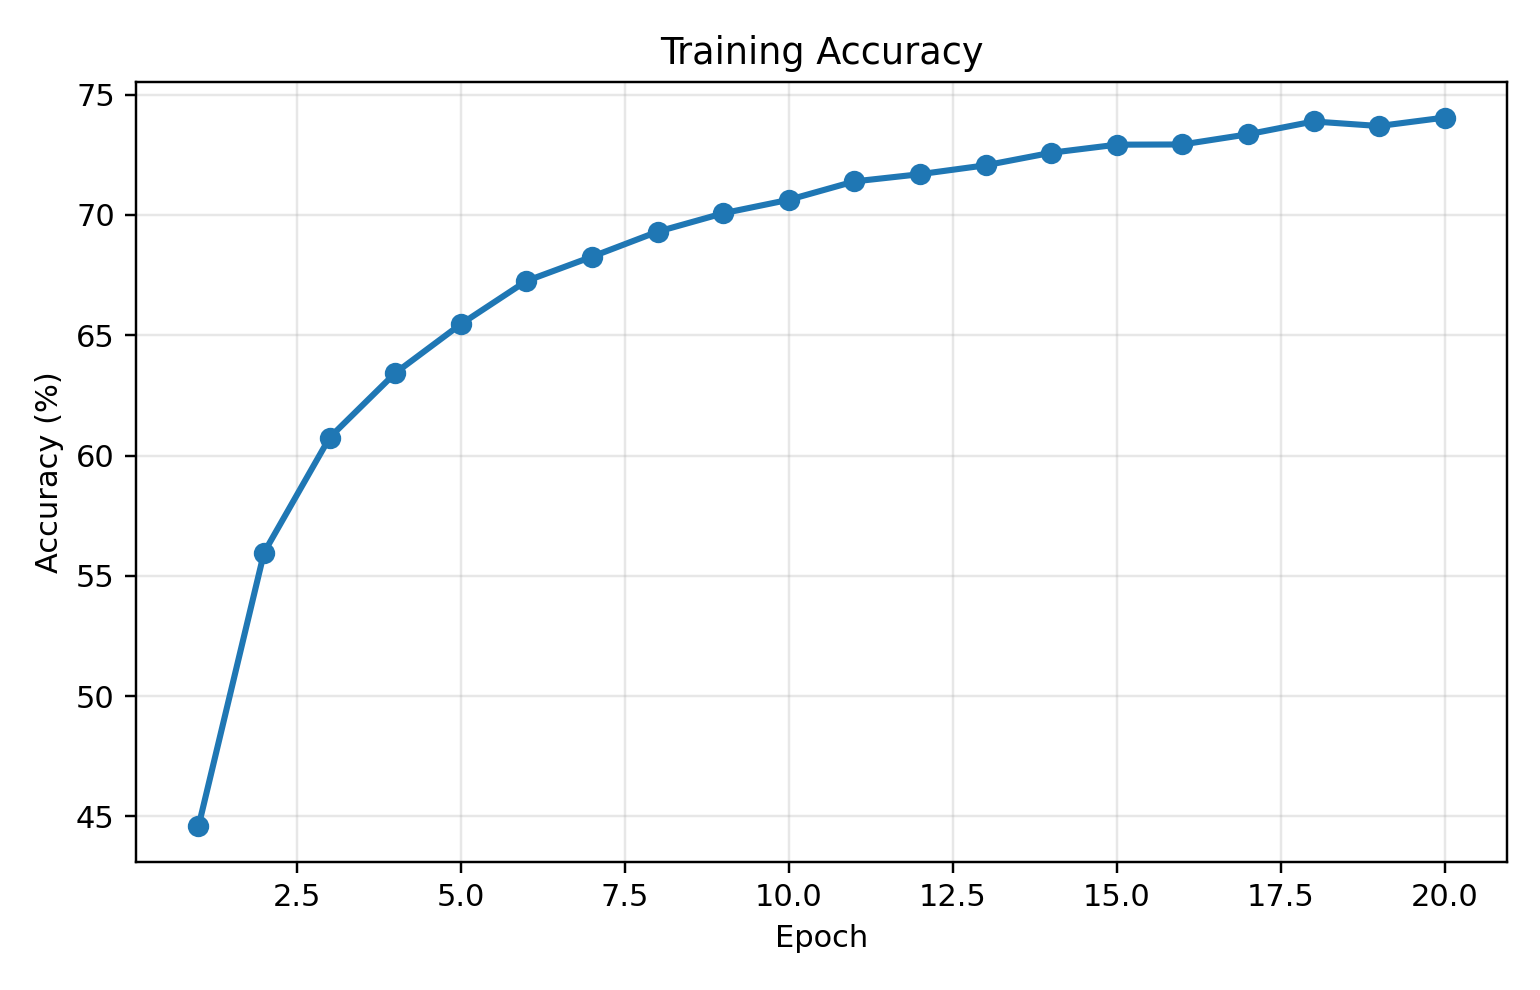


training_loss.png


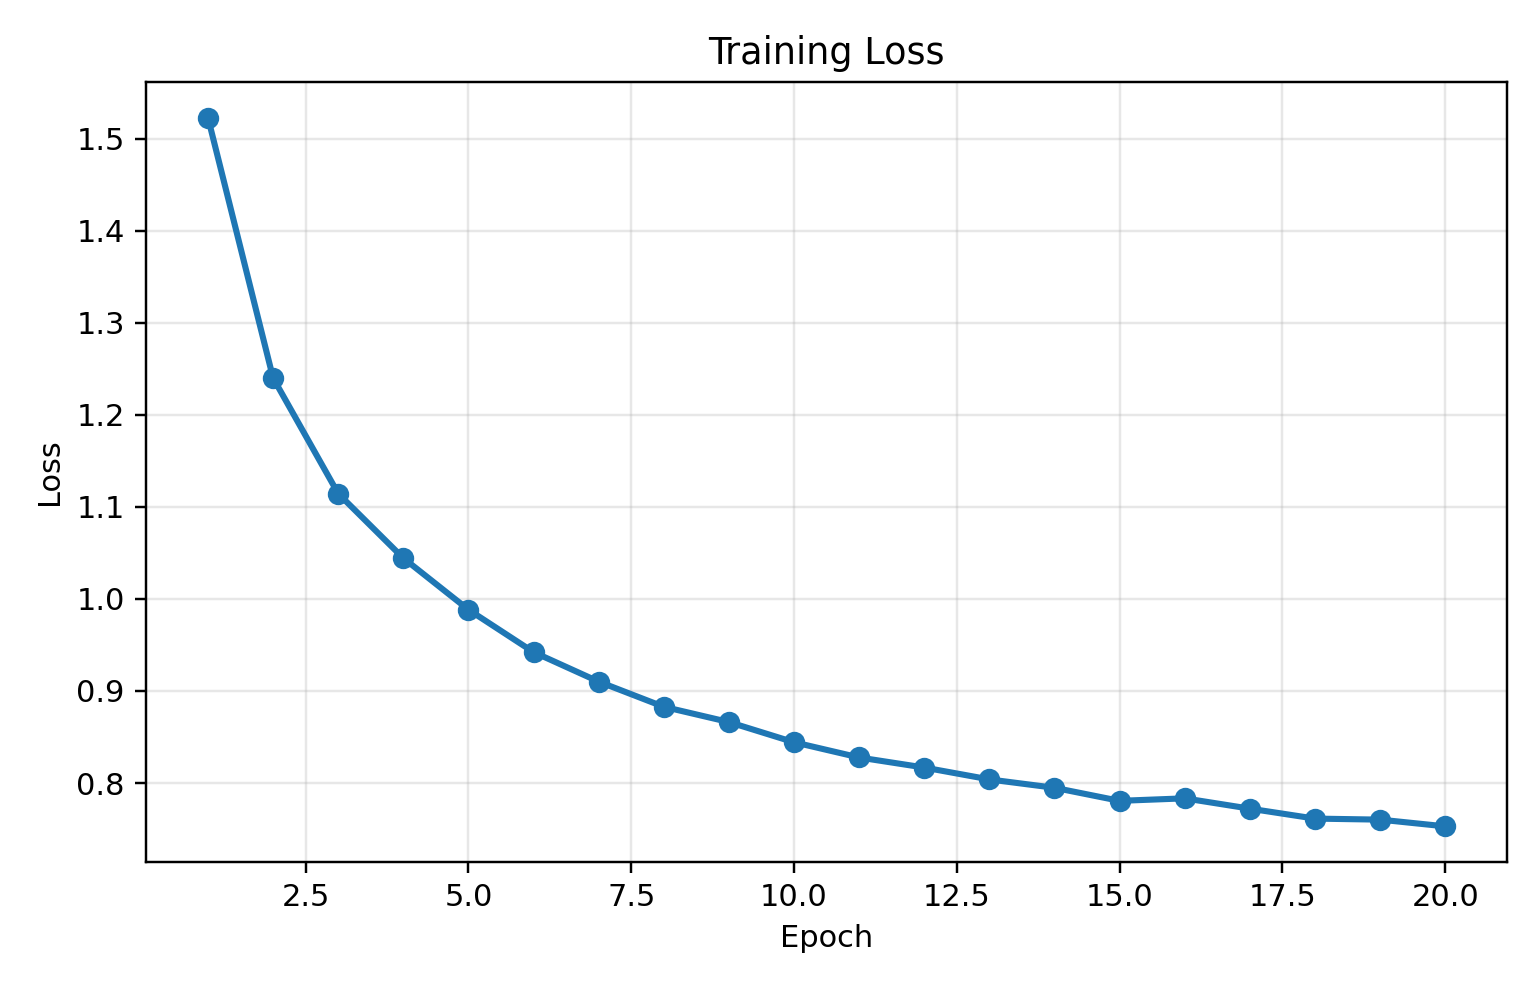


validation_accuracy.png


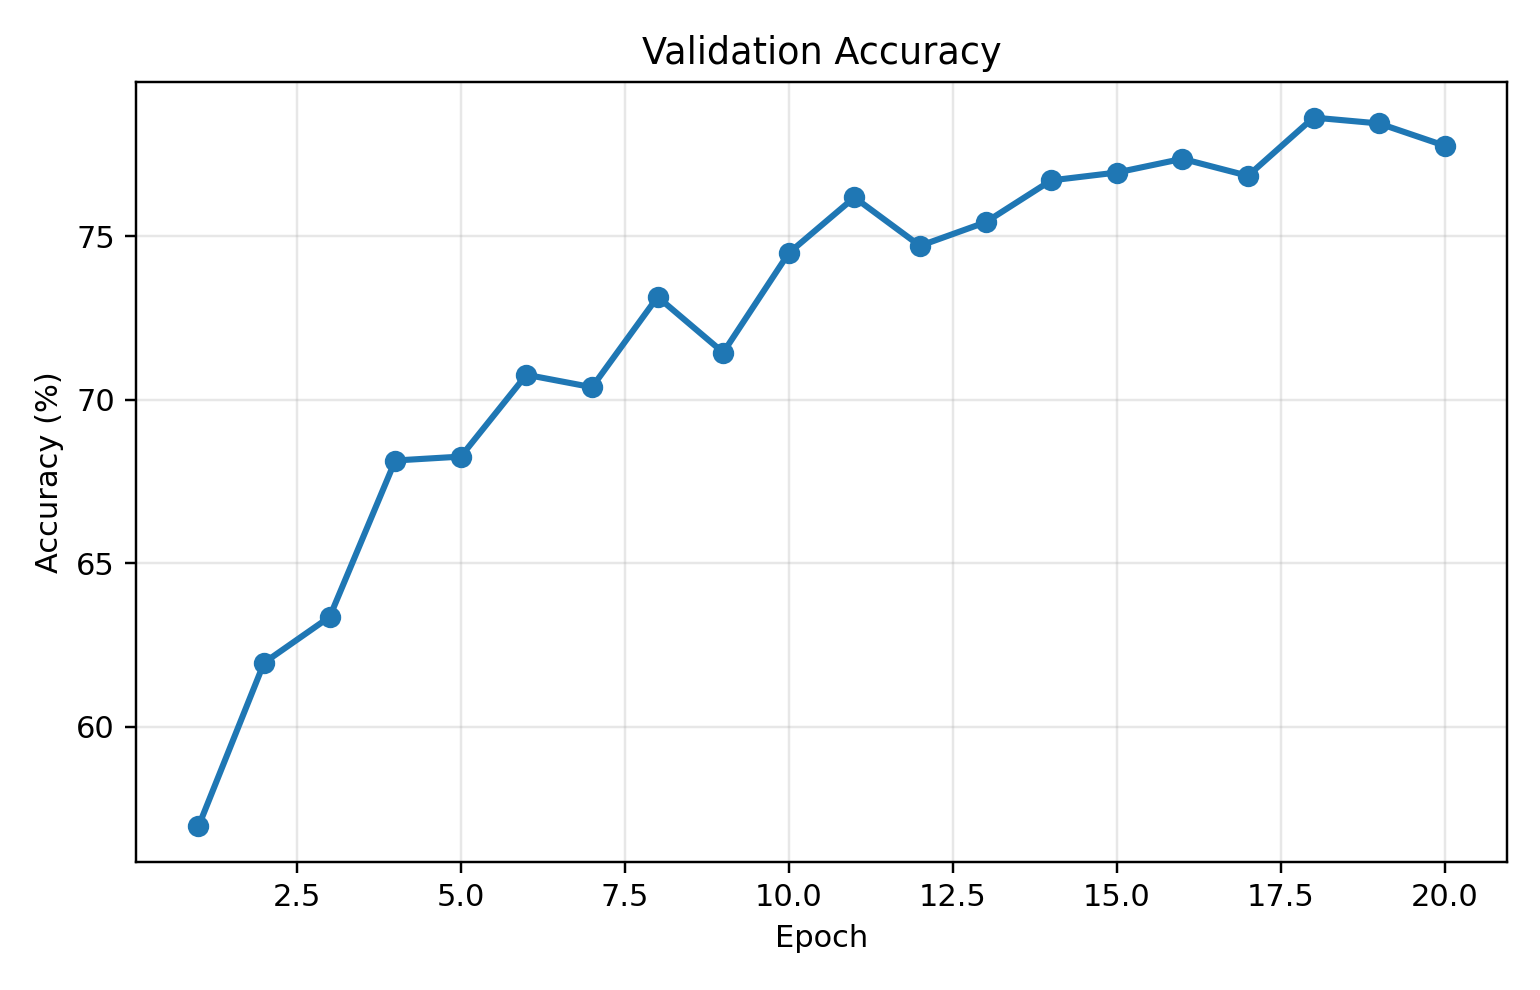


validation_loss.png


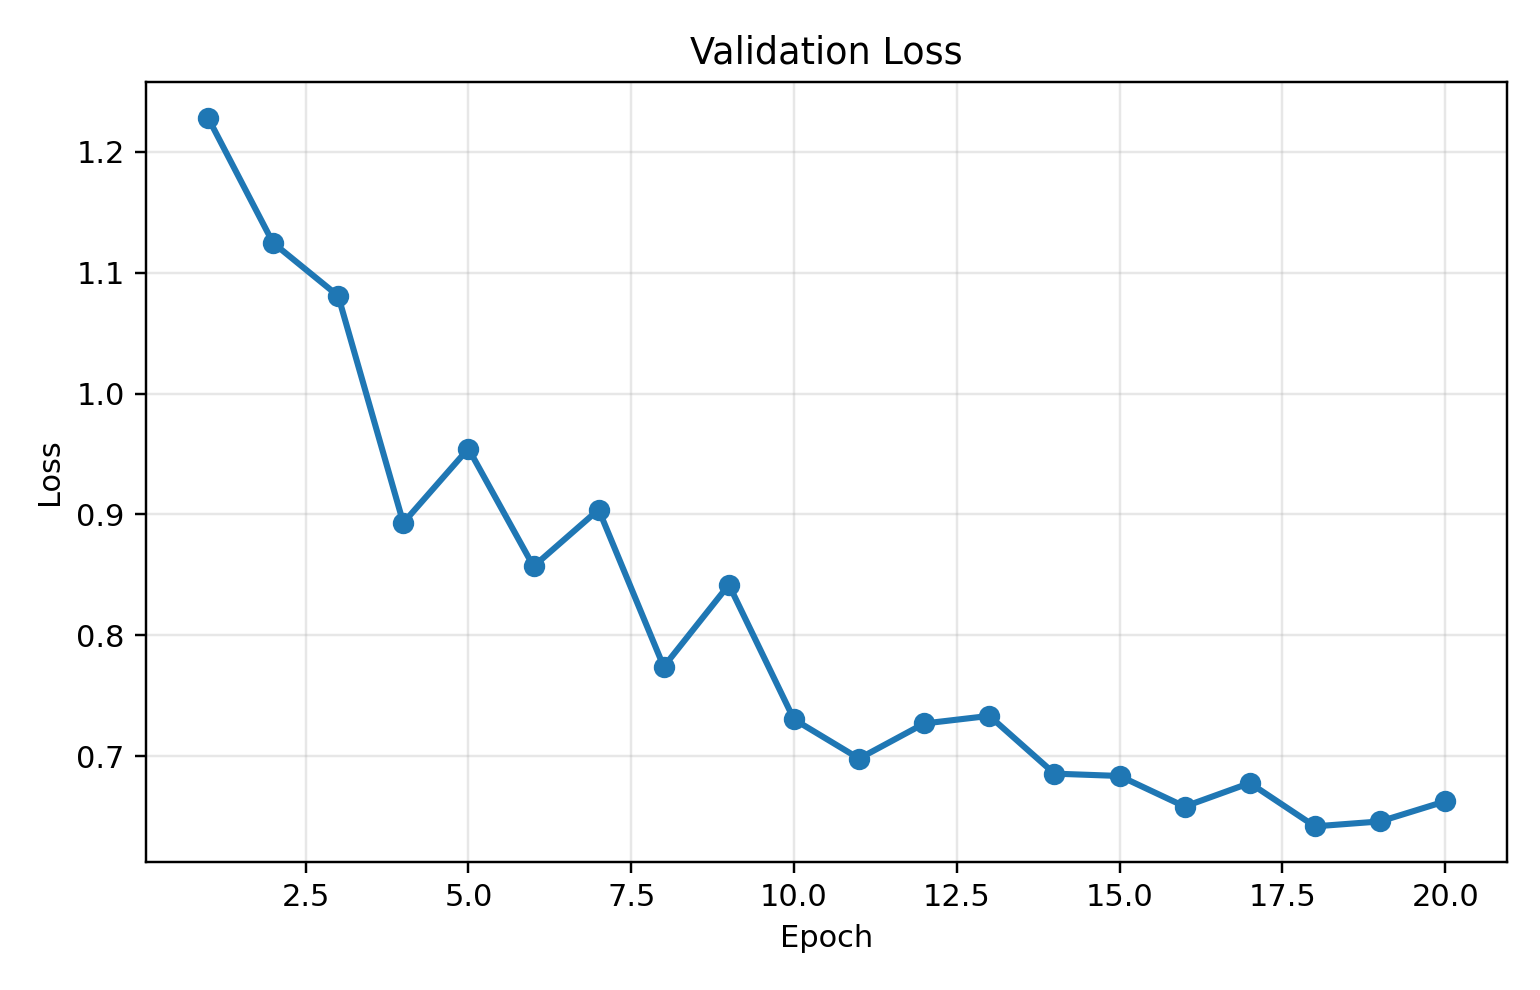

In [62]:
final_plots = [
    "training_accuracy.png",
    "training_loss.png",
    "validation_accuracy.png",
    "validation_loss.png",
]

for plot in final_plots:

    print("\n" + plot)

    display(
        Image(
            filename=f"outputs/best_plots/{plot}"
        )
    )

In [63]:
best_history = pd.read_csv(
    "outputs/best_history.csv"
)

best_epoch_index = (
    best_history[
        "validation_accuracy"
    ].idxmax()
)

best_epoch = (
    best_history.loc[
        best_epoch_index
    ]
)

print(
    "Best epoch from final "
    "reproducibility run:"
)

print(best_epoch)

Best epoch from final reproducibility run:
epoch                  18.000000
train_loss              0.761338
train_accuracy         73.884444
validation_loss         0.642014
validation_accuracy    78.620000
Name: 17, dtype: float64


In [64]:
from pathlib import Path
import shutil

SOURCE = Path(
    "/content/vgg6_workspace/"
    "VGG6-CIFAR10"
)

DESTINATION = Path(
    "/content/drive/MyDrive/"
    "VGG6-CIFAR10-Final"
)

if DESTINATION.exists():

    shutil.rmtree(
        DESTINATION
    )

shutil.copytree(
    SOURCE,
    DESTINATION,
    ignore=shutil.ignore_patterns(
        "data",
        "__pycache__",
        "*.pyc",
        "wandb"
    )
)

print(
    "Final project saved to:"
)

print(
    DESTINATION
)

Final project saved to:
/content/drive/MyDrive/VGG6-CIFAR10-Final


In [65]:
import yaml

best_config = {
    "activation": best_run.config["activation"],
    "optimizer": best_run.config["optimizer"],
    "learning_rate": float(best_run.config["learning_rate"]),
    "batch_size": int(best_run.config["batch_size"]),
    "epochs": int(best_run.config["epochs"]),
    "weight_decay": float(best_run.config.get("weight_decay", 0.0005)),
    "seed": int(best_run.config.get("seed", 42)),
    "workers": 2,
    "data_dir": "data",
    "use_wandb": True,
    "wandb_project": "vgg6-cifar10",
    "checkpoint_path": "checkpoints/best_model.pt",
    "history_path": "outputs/best_history.csv",
}

with open("configs/best.yaml", "w") as f:
    yaml.safe_dump(best_config, f, sort_keys=False)

print(open("configs/best.yaml").read())

activation: gelu
optimizer: rmsprop
learning_rate: 0.0001
batch_size: 32
epochs: 20
weight_decay: 0.0005
seed: 42
workers: 2
data_dir: data
use_wandb: true
wandb_project: vgg6-cifar10
checkpoint_path: checkpoints/best_model.pt
history_path: outputs/best_history.csv



In [66]:
!python -m src.train --config configs/best.yaml

Device: cuda
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 90bl2ahb (0.2s)
wandb: ⣯ setting up run 90bl2ahb (0.2s)
wandb: ⣟ setting up run 90bl2ahb (0.2s)
wandb: ⡿ setting up run 90bl2ahb (0.2s)
wandb: ⢿ setting up run 90bl2ahb (0.2s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /content/vgg6_workspace/VGG6-CIFAR10/wandb/run-20261030_074409-90bl2ahb
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vacant-hex-3
wandb: ⭐️ View project at https://wandb.ai/cs25m537-indian-institute-of-technology-madras/vgg6-ci

In [67]:
!python -m src.evaluate \
    --config configs/best.yaml \
    --checkpoint checkpoints/best_model.pt \
    --split both

{'validation': {'loss': 0.6420137705802917, 'accuracy': 78.62}, 'test': {'loss': 0.6617465424537659, 'accuracy': 77.45}}


In [68]:
from src.evaluate import evaluate_checkpoint
import json

final_results = evaluate_checkpoint(
    config_path="configs/best.yaml",
    checkpoint_path="checkpoints/best_model.pt",
    split="both"
)

with open(
    "outputs/final_evaluation.json",
    "w"
) as file:

    json.dump(
        final_results,
        file,
        indent=4
    )

print(
    json.dumps(
        final_results,
        indent=4
    )
)

{'validation': {'loss': 0.6420137705802917, 'accuracy': 78.62}, 'test': {'loss': 0.6617465424537659, 'accuracy': 77.45}}
{
    "validation": {
        "loss": 0.6420137705802917,
        "accuracy": 78.62
    },
    "test": {
        "loss": 0.6617465424537659,
        "accuracy": 77.45
    }
}


In [69]:
!python -m src.plot_history \
    --history outputs/best_history.csv \
    --output-dir outputs/best_plots

In [70]:
from pathlib import Path

for filename in [
    "training_accuracy.png",
    "training_loss.png",
    "validation_accuracy.png",
    "validation_loss.png",
]:

    path = Path("outputs/best_plots") / filename

    print(
        f"{filename:30}",
        "FOUND" if path.exists() else "MISSING"
    )

training_accuracy.png          FOUND
training_loss.png              FOUND
validation_accuracy.png        FOUND
validation_loss.png            FOUND


In [71]:
import pandas as pd

best_history = pd.read_csv(
    "outputs/best_history.csv"
)

best_epoch_index = (
    best_history[
        "validation_accuracy"
    ]
    .idxmax()
)

best_epoch = (
    best_history.loc[
        best_epoch_index
    ]
)

print("FINAL REPRODUCIBILITY RUN")
print("=" * 60)

print(
    "Best epoch             :",
    int(best_epoch["epoch"])
)

print(
    "Training accuracy      :",
    f"{best_epoch['train_accuracy']:.2f}%"
)

print(
    "Training loss          :",
    f"{best_epoch['train_loss']:.4f}"
)

print(
    "Validation accuracy    :",
    f"{best_epoch['validation_accuracy']:.2f}%"
)

print(
    "Validation loss        :",
    f"{best_epoch['validation_loss']:.4f}"
)

FINAL REPRODUCIBILITY RUN
Best epoch             : 18
Training accuracy      : 73.88%
Training loss          : 0.7613
Validation accuracy    : 78.62%
Validation loss        : 0.6420


In [72]:
sweep_best_validation = 78.62

rerun_best_validation = float(
    best_epoch[
        "validation_accuracy"
    ]
)

difference = (
    rerun_best_validation
    - sweep_best_validation
)

print("Q4 REPRODUCIBILITY CHECK")
print("=" * 50)

print(
    f"Sweep validation accuracy : "
    f"{sweep_best_validation:.2f}%"
)

print(
    f"Rerun validation accuracy : "
    f"{rerun_best_validation:.2f}%"
)

print(
    f"Difference                : "
    f"{difference:+.2f} percentage points"
)

Q4 REPRODUCIBILITY CHECK
Sweep validation accuracy : 78.62%
Rerun validation accuracy : 78.62%
Difference                : +0.00 percentage points


In [73]:
import wandb
import pandas as pd

api = wandb.Api()

ACTIVATION_SWEEP = (
    "cs25m537-indian-institute-of-technology-madras/"
    "uncategorized/eq18u0hc"
)

sweep = api.sweep(ACTIVATION_SWEEP)

activation_results = []

for run in sweep.runs:

    if (
        run.state == "finished"
        and run.summary.get(
            "best_validation_accuracy"
        ) is not None
    ):

        activation_results.append({
            "Activation":
                run.config.get("activation"),

            "Best Validation Accuracy (%)":
                run.summary.get(
                    "best_validation_accuracy"
                ),

            "Final Test Accuracy (%)":
                run.summary.get(
                    "final_test_accuracy"
                ),
        })

activation_df = pd.DataFrame(
    activation_results
)

activation_df = (
    activation_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print(activation_df.to_string(index=False))

activation_df.to_csv(
    "outputs/activation_results.csv",
    index=False
)

Activation  Best Validation Accuracy (%)  Final Test Accuracy (%)
      gelu                         78.86                    78.47
      relu                         78.26                    79.04
      silu                         75.46                    75.43
      tanh                         65.86                    66.54
   sigmoid                         33.98                    34.04


In [74]:
import wandb
import pandas as pd
from pathlib import Path

# Use the activation sweep ID created earlier.
# Example:
# ACTIVATION_SWEEP = "ENTITY/PROJECT/SWEEP_ID"

api = wandb.Api()

sweep = api.sweep(ACTIVATION_SWEEP)

activation_results = []

for run in sweep.runs:

    # Include only successfully completed runs
    if (
        run.state == "finished"
        and run.summary.get("best_validation_accuracy") is not None
    ):

        activation_results.append({
            "Activation": run.config.get("activation"),

            "Best Validation Accuracy (%)":
                float(
                    run.summary.get(
                        "best_validation_accuracy"
                    )
                ),

            "Final Test Accuracy (%)":
                float(
                    run.summary.get(
                        "final_test_accuracy"
                    )
                )
                if run.summary.get(
                    "final_test_accuracy"
                ) is not None
                else None,

            "Run Name":
                run.name
        })

if not activation_results:
    raise RuntimeError(
        "No completed activation sweep runs "
        "with validation accuracy were found."
    )

activation_df = pd.DataFrame(
    activation_results
)

# Keep the best completed run if an activation
# was accidentally executed more than once.
activation_df = (
    activation_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .drop_duplicates(
        subset=["Activation"],
        keep="first"
    )
    .reset_index(drop=True)
)

print(
    activation_df.to_string(
        index=False
    )
)

Activation  Best Validation Accuracy (%)  Final Test Accuracy (%)       Run Name
      gelu                         78.86                    78.47  polar-sweep-5
      relu                         78.26                    79.04  vocal-sweep-1
      silu                         75.46                    75.43 earthy-sweep-4
      tanh                         65.86                    66.54   easy-sweep-3
   sigmoid                         33.98                    34.04 floral-sweep-2


In [75]:
required_activations = {
    "relu",
    "sigmoid",
    "tanh",
    "silu",
    "gelu"
}

found_activations = set(
    activation_df[
        "Activation"
    ]
    .str.lower()
)

missing_activations = (
    required_activations
    - found_activations
)

if missing_activations:

    raise RuntimeError(
        "Activation sweep is incomplete. "
        f"Missing: {sorted(missing_activations)}"
    )

print(
    "SUCCESS: Results for all five "
    "activation functions are available."
)

SUCCESS: Results for all five activation functions are available.


In [76]:
output_dir = Path(
    "outputs/q2a"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

activation_df.to_csv(
    output_dir /
    "activation_results.csv",
    index=False
)

print(
    "Results saved to:",
    output_dir /
    "activation_results.csv"
)

Results saved to: outputs/q2a/activation_results.csv


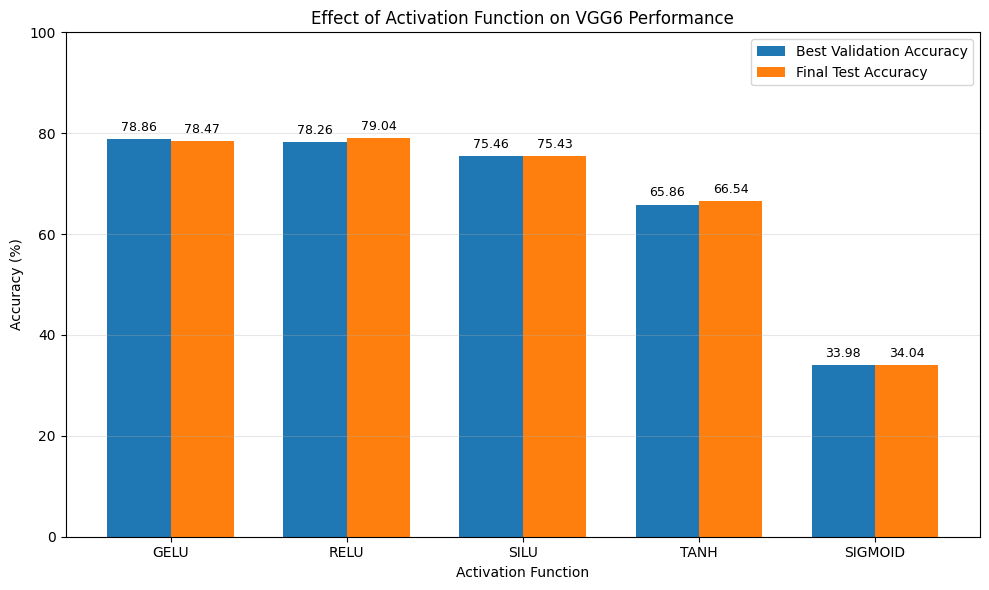

Figure saved to: outputs/q2a/activation_function_comparison.png


In [77]:
import matplotlib.pyplot as plt
import numpy as np

# Sort by validation accuracy for easy comparison
plot_df = (
    activation_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

x = np.arange(
    len(plot_df)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(10, 6)
)

validation_bars = ax.bar(
    x - width / 2,
    plot_df[
        "Best Validation Accuracy (%)"
    ],
    width,
    label="Best Validation Accuracy"
)

test_bars = ax.bar(
    x + width / 2,
    plot_df[
        "Final Test Accuracy (%)"
    ],
    width,
    label="Final Test Accuracy"
)

ax.set_xlabel(
    "Activation Function"
)

ax.set_ylabel(
    "Accuracy (%)"
)

ax.set_title(
    "Effect of Activation Function "
    "on VGG6 Performance"
)

ax.set_xticks(x)

ax.set_xticklabels(
    plot_df["Activation"]
    .str.upper()
)

ax.set_ylim(
    0,
    100
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

# Add numerical values above validation bars
for bar in validation_bars:

    value = bar.get_height()

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add numerical values above test bars
for bar in test_bars:

    value = bar.get_height()

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

figure_path = (
    output_dir /
    "activation_function_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    figure_path
)

In [78]:
best_activation = (
    activation_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .iloc[0]
)

worst_activation = (
    activation_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=True
    )
    .iloc[0]
)

best_test = (
    activation_df
    .sort_values(
        "Final Test Accuracy (%)",
        ascending=False
    )
    .iloc[0]
)

validation_spread = (
    best_activation[
        "Best Validation Accuracy (%)"
    ]
    -
    worst_activation[
        "Best Validation Accuracy (%)"
    ]
)

print(
    "Best validation activation:",
    best_activation["Activation"]
)

print(
    "Best validation accuracy:",
    f"{best_activation['Best Validation Accuracy (%)']:.2f}%"
)

print(
    "Best test activation:",
    best_test["Activation"]
)

print(
    "Best test accuracy:",
    f"{best_test['Final Test Accuracy (%)']:.2f}%"
)

print(
    "Lowest validation activation:",
    worst_activation["Activation"]
)

print(
    "Validation accuracy spread:",
    f"{validation_spread:.2f} percentage points"
)

Best validation activation: gelu
Best validation accuracy: 78.86%
Best test activation: relu
Best test accuracy: 79.04%
Lowest validation activation: sigmoid
Validation accuracy spread: 44.88 percentage points


In [79]:
import wandb
import pandas as pd
from pathlib import Path

api = wandb.Api()

# Use the optimizer sweep ID already created earlier.
# OPTIMIZER_SWEEP = "ENTITY/PROJECT/SWEEP_ID"

sweep = api.sweep(OPTIMIZER_SWEEP)

optimizer_results = []

for run in sweep.runs:

    if (
        run.state == "finished"
        and run.summary.get(
            "best_validation_accuracy"
        ) is not None
    ):

        optimizer_results.append({
            "Optimizer":
                run.config.get("optimizer"),

            "Best Validation Accuracy (%)":
                float(
                    run.summary[
                        "best_validation_accuracy"
                    ]
                ),

            "Final Test Accuracy (%)":
                float(
                    run.summary[
                        "final_test_accuracy"
                    ]
                )
                if run.summary.get(
                    "final_test_accuracy"
                ) is not None
                else None,

            "Run Name":
                run.name,
        })

if not optimizer_results:
    raise RuntimeError(
        "No completed optimizer sweep runs found."
    )

optimizer_df = pd.DataFrame(
    optimizer_results
)

# If an optimizer was accidentally run more than once,
# retain its highest-validation run.
optimizer_df = (
    optimizer_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .drop_duplicates(
        subset=["Optimizer"],
        keep="first"
    )
    .reset_index(drop=True)
)

print(
    optimizer_df.to_string(
        index=False
    )
)

   Optimizer  Best Validation Accuracy (%)  Final Test Accuracy (%)            Run Name
        adam                         78.26                    79.04   wandering-sweep-3
       nadam                         77.02                    77.52 distinctive-sweep-6
         sgd                         63.30                    63.16       fresh-sweep-1
nesterov_sgd                         62.86                    62.73      unique-sweep-2
     rmsprop                         57.02                    56.90       lilac-sweep-5
     adagrad                         56.18                    56.03      atomic-sweep-4


In [80]:
required_optimizers = {
    "sgd",
    "nesterov_sgd",
    "adam",
    "adagrad",
    "rmsprop",
    "nadam",
}

found_optimizers = set(
    optimizer_df[
        "Optimizer"
    ]
    .str.lower()
)

missing = (
    required_optimizers
    - found_optimizers
)

if missing:
    raise RuntimeError(
        f"Missing optimizer results: "
        f"{sorted(missing)}"
    )

print(
    "SUCCESS: All six optimizer "
    "results are available."
)

SUCCESS: All six optimizer results are available.


In [81]:
output_dir = Path(
    "outputs/q2b"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

optimizer_df.to_csv(
    output_dir /
    "optimizer_results.csv",
    index=False
)

print(
    optimizer_df.to_string(
        index=False
    )
)

   Optimizer  Best Validation Accuracy (%)  Final Test Accuracy (%)            Run Name
        adam                         78.26                    79.04   wandering-sweep-3
       nadam                         77.02                    77.52 distinctive-sweep-6
         sgd                         63.30                    63.16       fresh-sweep-1
nesterov_sgd                         62.86                    62.73      unique-sweep-2
     rmsprop                         57.02                    56.90       lilac-sweep-5
     adagrad                         56.18                    56.03      atomic-sweep-4


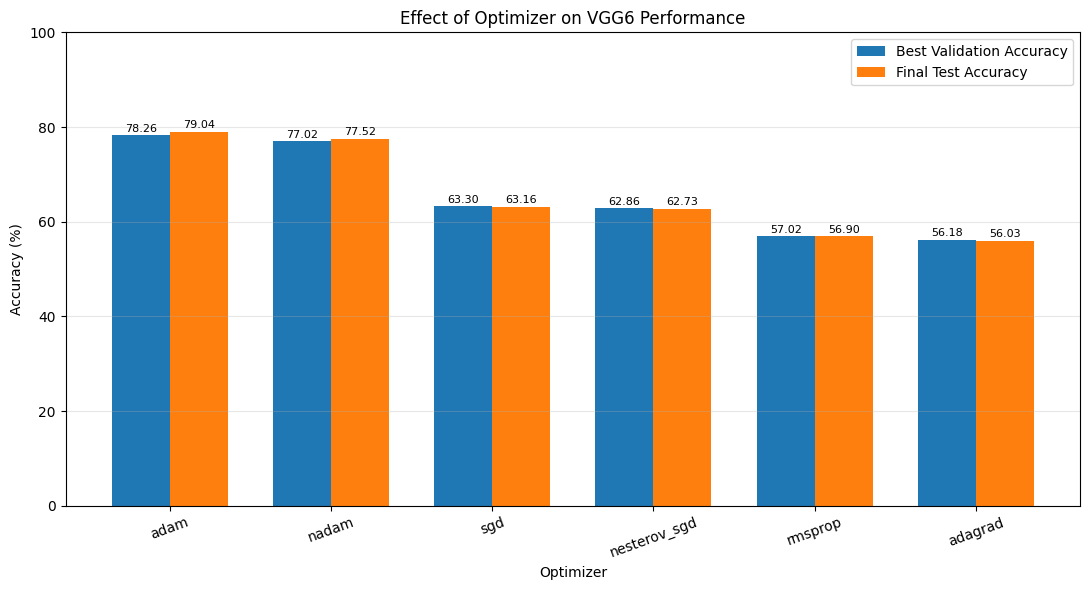

Saved: outputs/q2b/optimizer_comparison.png


In [82]:
#Activation Comparison Plot
import matplotlib.pyplot as plt
import numpy as np

plot_df = (
    optimizer_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

x = np.arange(
    len(plot_df)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(11, 6)
)

validation_bars = ax.bar(
    x - width / 2,
    plot_df[
        "Best Validation Accuracy (%)"
    ],
    width,
    label="Best Validation Accuracy"
)

test_bars = ax.bar(
    x + width / 2,
    plot_df[
        "Final Test Accuracy (%)"
    ],
    width,
    label="Final Test Accuracy"
)

ax.set_xlabel(
    "Optimizer"
)

ax.set_ylabel(
    "Accuracy (%)"
)

ax.set_title(
    "Effect of Optimizer on VGG6 Performance"
)

ax.set_xticks(x)

ax.set_xticklabels(
    plot_df["Optimizer"],
    rotation=20
)

ax.set_ylim(
    0,
    100
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

for bars in [
    validation_bars,
    test_bars
]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value + 0.7,
            f"{value:.2f}",
            ha="center",
            fontsize=8
        )

plt.tight_layout()

figure_path = (
    output_dir /
    "optimizer_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)


In [84]:
ranking = (
    optimizer_df
    .sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    )
)

print(
    "Optimizer ranking based on "
    "validation accuracy:"
)

for position, (_, row) in enumerate(
    ranking.iterrows(),
    start=1
):

    print(
        f"{position}. "
        f"{row['Optimizer']} - "
        f"{row['Best Validation Accuracy (%)']:.2f}%"
    )

Optimizer ranking based on validation accuracy:
1. adam - 78.26%
2. nadam - 77.02%
3. sgd - 63.30%
4. nesterov_sgd - 62.86%
5. rmsprop - 57.02%
6. adagrad - 56.18%


In [85]:
best_optimizer = ranking.iloc[0]

worst_optimizer = ranking.iloc[-1]

spread = (
    best_optimizer[
        "Best Validation Accuracy (%)"
    ]
    -
    worst_optimizer[
        "Best Validation Accuracy (%)"
    ]
)

print()

print(
    "Best optimizer:",
    best_optimizer["Optimizer"]
)

print(
    "Best validation accuracy:",
    f"{best_optimizer['Best Validation Accuracy (%)']:.2f}%"
)

print(
    "Lowest optimizer:",
    worst_optimizer["Optimizer"]
)

print(
    "Validation accuracy spread:",
    f"{spread:.2f} percentage points"
)


Best optimizer: adam
Best validation accuracy: 78.26%
Lowest optimizer: adagrad
Validation accuracy spread: 22.08 percentage points


In [94]:
COMBINED_SWEEP

'cs25m537-indian-institute-of-technology-madras/uncategorized/x5eic8a8'

In [97]:
Q2C_SWEEP = COMBINED_SWEEP

In [102]:
import wandb
import pandas as pd
import numpy as np

# Use your Q2(c) sweep
# If you are currently using the combined sweep:
Q2C_SWEEP = COMBINED_SWEEP

api = wandb.Api()

sweep = api.sweep(Q2C_SWEEP)

records = []

for run in sweep.runs:

    if run.state != "finished":
        continue

    config = dict(run.config)
    summary = dict(run.summary)

    best_val = summary.get(
        "best_validation_accuracy"
    )

    if best_val is None:
        continue

    records.append({

        "Run":
            run.name,

        "activation":
            config.get("activation"),

        "optimizer":
            config.get("optimizer"),

        "learning_rate":
            config.get("learning_rate"),

        "batch_size":
            config.get("batch_size"),

        "epochs":
            config.get("epochs"),

        "weight_decay":
            config.get("weight_decay"),

        "seed":
            config.get("seed"),

        "best_validation_accuracy":
            float(best_val),

        "final_test_accuracy":
            (
                float(
                    summary.get(
                        "final_test_accuracy"
                    )
                )
                if summary.get(
                    "final_test_accuracy"
                ) is not None
                else np.nan
            ),
    })


if len(records) == 0:

    raise RuntimeError(
        "No completed W&B runs with "
        "best_validation_accuracy were found."
    )


q2c_df = pd.DataFrame(records)


print(
    "Extracted",
    len(q2c_df),
    "completed W&B runs."
)

print("\nColumns:")
print(
    q2c_df.columns.tolist()
)

display(
    q2c_df.head()
)

Extracted 15 completed W&B runs.

Columns:
['Run', 'activation', 'optimizer', 'learning_rate', 'batch_size', 'epochs', 'weight_decay', 'seed', 'best_validation_accuracy', 'final_test_accuracy']


,Run,activation,optimizer,learning_rate,batch_size,epochs,weight_decay,seed,best_validation_accuracy,final_test_accuracy
0,flowing-sweep-1,relu,nadam,0.0001,64,10,0.0005,42,60.50,60.89
1,feasible-sweep-2,relu,adam,0.0010,64,20,0.0005,42,78.26,79.04
2,comfy-sweep-3,relu,nadam,0.0001,32,20,0.0005,42,69.78,69.41
3,mild-sweep-4,silu,rmsprop,0.0005,128,30,0.0005,42,69.46,69.93
4,upbeat-sweep-5,relu,nadam,0.0005,32,10,0.0005,42,72.50,73.18


In [103]:
print("Q2(c) PARAMETERS FOUND IN W&B")
print("=" * 60)

print(
    "Learning rates:",
    sorted(
        q2c_df[
            "learning_rate"
        ].dropna().unique()
    )
)

print(
    "Batch sizes:",
    sorted(
        q2c_df[
            "batch_size"
        ].dropna().unique()
    )
)

print(
    "Epoch values:",
    sorted(
        q2c_df[
            "epochs"
        ].dropna().unique()
    )
)

print(
    "Optimizers:",
    sorted(
        q2c_df[
            "optimizer"
        ].dropna().unique()
    )
)

print(
    "Activations:",
    sorted(
        q2c_df[
            "activation"
        ].dropna().unique()
    )
)

Q2(c) PARAMETERS FOUND IN W&B
Learning rates: [np.float64(0.0001), np.float64(0.0005), np.float64(0.001), np.float64(0.005)]
Batch sizes: [np.int64(32), np.int64(64), np.int64(128)]
Epoch values: [np.int64(10), np.int64(20), np.int64(30)]
Optimizers: ['adam', 'nadam', 'rmsprop']
Activations: ['gelu', 'relu', 'silu']


In [105]:
num_optimizers = (
    q2c_df["optimizer"]
    .dropna()
    .nunique()
)

num_activations = (
    q2c_df["activation"]
    .dropna()
    .nunique()
)


if (
    num_optimizers == 1
    and
    num_activations == 1
):

    print(
        "CONTROLLED Q2(c) SWEEP"
    )

    print(
        "Optimizer:",
        q2c_df[
            "optimizer"
        ].dropna().iloc[0]
    )

    print(
        "Activation:",
        q2c_df[
            "activation"
        ].dropna().iloc[0]
    )

    print(
        "\nLearning rate, batch size and "
        "epochs can be compared while "
        "optimizer and activation remain fixed."
    )

else:

    print(
        "WARNING:"
    )

    print(
        "This sweep changes optimizer and/or "
        "activation in addition to LR, batch "
        "size and epochs."
    )

    print(
        "The plots therefore show associations, "
        "not isolated effects of Q2(c) parameters."
    )

This sweep changes optimizer and/or activation in addition to LR, batch size and epochs.
The plots therefore show associations, not isolated effects of Q2(c) parameters.


In [106]:
OUTPUT_DIR = Path(
    "outputs/q2c"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


q2c_df.to_csv(
    OUTPUT_DIR /
    "q2c_results.csv",
    index=False
)


print(
    "Saved:",
    OUTPUT_DIR /
    "q2c_results.csv"
)

Saved: outputs/q2c/q2c_results.csv


In [107]:
best_q2c = q2c_df.iloc[0]

print("BEST Q2(c) CONFIGURATION")
print("=" * 60)

print(
    "Activation          :",
    best_q2c["activation"]
)

print(
    "Optimizer           :",
    best_q2c["optimizer"]
)

print(
    "Learning rate       :",
    best_q2c["learning_rate"]
)

print(
    "Batch size          :",
    int(
        best_q2c[
            "batch_size"
        ]
    )
)

print(
    "Epochs              :",
    int(
        best_q2c[
            "epochs"
        ]
    )
)

print(
    "Validation accuracy :",
    f"{best_q2c['best_validation_accuracy']:.2f}%"
)

if pd.notna(
    best_q2c[
        "final_test_accuracy"
    ]
):

    print(
        "Test accuracy       :",
        f"{best_q2c['final_test_accuracy']:.2f}%"
    )

BEST Q2(c) CONFIGURATION
Activation          : relu
Optimizer           : nadam
Learning rate       : 0.0001
Batch size          : 64
Epochs              : 10
Validation accuracy : 60.50%
Test accuracy       : 60.89%


In [112]:
# ============================================================
# Q2(c) - Rebuild summary tables with consistent column names
# ============================================================

import pandas as pd

# Check q2c_df exists
if "q2c_df" not in globals():
    raise RuntimeError(
        "q2c_df is not available. "
        "Run the W&B extraction cell first."
    )

required_columns = [
    "Run",
    "learning_rate",
    "batch_size",
    "epochs",
    "best_validation_accuracy",
]

missing = [
    col for col in required_columns
    if col not in q2c_df.columns
]

if missing:
    raise RuntimeError(
        f"Missing columns in q2c_df: {missing}\n"
        f"Available columns: {q2c_df.columns.tolist()}"
    )


# ------------------------------
# Learning rate summary
# ------------------------------

lr_summary = (
    q2c_df
    .dropna(
        subset=[
            "learning_rate",
            "best_validation_accuracy",
        ]
    )
    .groupby("learning_rate")
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
    .sort_values("learning_rate")
)


# ------------------------------
# Batch size summary
# ------------------------------

batch_summary = (
    q2c_df
    .dropna(
        subset=[
            "batch_size",
            "best_validation_accuracy",
        ]
    )
    .groupby("batch_size")
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
    .sort_values("batch_size")
)


# ------------------------------
# Epoch summary
# ------------------------------

epoch_summary = (
    q2c_df
    .dropna(
        subset=[
            "epochs",
            "best_validation_accuracy",
        ]
    )
    .groupby("epochs")
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
    .sort_values("epochs")
)


print("SUCCESS: Q2(c) summary tables rebuilt.")

print("\nLearning Rate Summary")
display(lr_summary)

print("\nBatch Size Summary")
display(batch_summary)

print("\nEpoch Summary")
display(epoch_summary)

SUCCESS: Q2(c) summary tables rebuilt.

Learning Rate Summary


,learning_rate,mean_validation_accuracy,best_validation_accuracy,runs
0,0.0001,70.652,78.62,5
1,0.0005,71.852,74.28,5
2,0.0010,70.660,78.40,4
3,0.0050,71.560,71.56,1



Batch Size Summary


,batch_size,mean_validation_accuracy,best_validation_accuracy,runs
0,32,70.888,78.62,5
1,64,69.380,78.26,2
2,128,71.690,78.40,8



Epoch Summary


,epochs,mean_validation_accuracy,best_validation_accuracy,runs
0,10,67.52,72.50,4
1,20,75.34,78.62,5
2,30,69.99,78.40,6


In [114]:
# ============================================================
# Q2(c) - Hyperparameter effects separated by optimizer
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs/q2c")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_columns = [
    "optimizer",
    "learning_rate",
    "batch_size",
    "epochs",
    "best_validation_accuracy",
]

missing_columns = [
    column
    for column in required_columns
    if column not in q2c_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {q2c_df.columns.tolist()}"
    )

# Remove incomplete rows
plot_df = (
    q2c_df
    .dropna(
        subset=[
            "optimizer",
            "learning_rate",
            "batch_size",
            "epochs",
            "best_validation_accuracy",
        ]
    )
    .copy()
)

print(
    "Optimizers present:",
    sorted(
        plot_df["optimizer"].unique()
    )
)

Optimizers present: ['adam', 'nadam', 'rmsprop']


In [115]:
# ============================================================
# Learning rate x optimizer
# ============================================================

lr_optimizer_summary = (
    plot_df
    .groupby(
        [
            "optimizer",
            "learning_rate",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)


# ============================================================
# Batch size x optimizer
# ============================================================

batch_optimizer_summary = (
    plot_df
    .groupby(
        [
            "optimizer",
            "batch_size",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)


# ============================================================
# Epochs x optimizer
# ============================================================

epoch_optimizer_summary = (
    plot_df
    .groupby(
        [
            "optimizer",
            "epochs",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)

In [118]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Validate data
# ============================================================

required_columns = [
    "Run",
    "optimizer",
    "activation",
    "learning_rate",
    "batch_size",
    "epochs",
    "best_validation_accuracy",
]

missing_columns = [
    col
    for col in required_columns
    if col not in q2c_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {q2c_df.columns.tolist()}"
    )


plot_df = (
    q2c_df
    .dropna(
        subset=[
            "optimizer",
            "activation",
            "learning_rate",
            "batch_size",
            "epochs",
            "best_validation_accuracy",
        ]
    )
    .copy()
)

# Create readable combined label
plot_df["Optimizer + Activation"] = (
    plot_df["optimizer"].str.upper()
    + " + "
    + plot_df["activation"].str.upper()
)

print("Configurations found:")

for config in sorted(
    plot_df["Optimizer + Activation"].unique()
):
    print(config)

Configurations found:
ADAM + RELU
ADAM + SILU
NADAM + RELU
NADAM + SILU
RMSPROP + GELU
RMSPROP + SILU


In [119]:
# ============================================================
# Learning Rate summary
# ============================================================

lr_summary = (
    plot_df
    .groupby(
        [
            "Optimizer + Activation",
            "learning_rate",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)


# ============================================================
# Batch Size summary
# ============================================================

batch_summary = (
    plot_df
    .groupby(
        [
            "Optimizer + Activation",
            "batch_size",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)


# ============================================================
# Epoch summary
# ============================================================

epoch_summary = (
    plot_df
    .groupby(
        [
            "Optimizer + Activation",
            "epochs",
        ]
    )
    .agg(
        mean_validation_accuracy=(
            "best_validation_accuracy",
            "mean",
        ),
        best_validation_accuracy=(
            "best_validation_accuracy",
            "max",
        ),
        runs=(
            "Run",
            "count",
        ),
    )
    .reset_index()
)

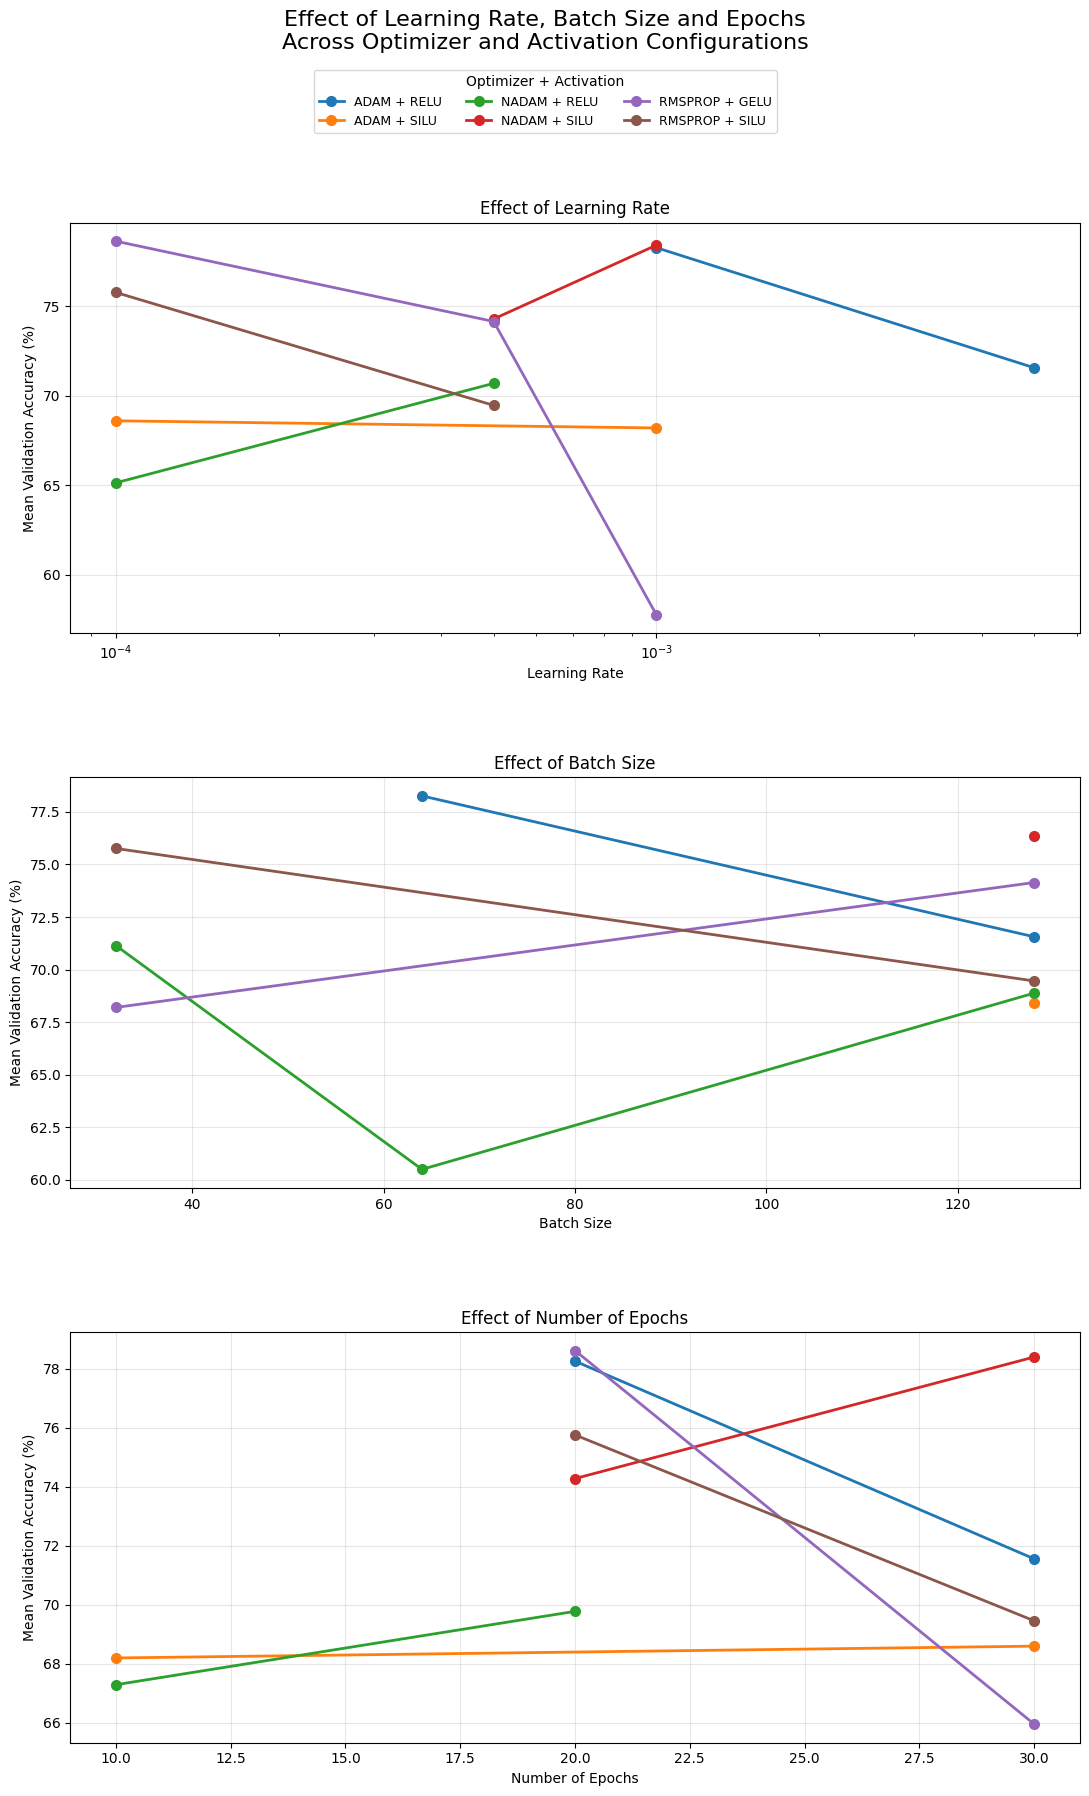

Vertical plot saved to: outputs/q2c/q2c_optimizer_activation_effects_vertical.png


In [122]:
# ============================================================
# Q2(c) - Learning Rate, Batch Size and Epoch Analysis
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs/q2c")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Get all optimizer + activation combinations automatically
configurations = sorted(
    plot_df["Optimizer + Activation"].unique()
)

# Create 3 plots vertically
fig, axes = plt.subplots(
    3,
    1,
    figsize=(11, 18)
)


# ============================================================
# 1. LEARNING RATE
# ============================================================

for config in configurations:

    temp = (
        lr_summary[
            lr_summary["Optimizer + Activation"] == config
        ]
        .sort_values("learning_rate")
    )

    if temp.empty:
        continue

    axes[0].plot(
        temp["learning_rate"],
        temp["mean_validation_accuracy"],
        marker="o",
        markersize=7,
        linewidth=2,
        label=config
    )


axes[0].set_xscale("log")

axes[0].set_xlabel(
    "Learning Rate"
)

axes[0].set_ylabel(
    "Mean Validation Accuracy (%)"
)

axes[0].set_title(
    "Effect of Learning Rate"
)

axes[0].grid(
    True,
    alpha=0.3
)


# ============================================================
# 2. BATCH SIZE
# ============================================================

for config in configurations:

    temp = (
        batch_summary[
            batch_summary["Optimizer + Activation"] == config
        ]
        .sort_values("batch_size")
    )

    if temp.empty:
        continue

    axes[1].plot(
        temp["batch_size"],
        temp["mean_validation_accuracy"],
        marker="o",
        markersize=7,
        linewidth=2,
        label=config
    )


axes[1].set_xlabel(
    "Batch Size"
)

axes[1].set_ylabel(
    "Mean Validation Accuracy (%)"
)

axes[1].set_title(
    "Effect of Batch Size"
)

axes[1].grid(
    True,
    alpha=0.3
)


# ============================================================
# 3. NUMBER OF EPOCHS
# ============================================================

for config in configurations:

    temp = (
        epoch_summary[
            epoch_summary["Optimizer + Activation"] == config
        ]
        .sort_values("epochs")
    )

    if temp.empty:
        continue

    axes[2].plot(
        temp["epochs"],
        temp["mean_validation_accuracy"],
        marker="o",
        markersize=7,
        linewidth=2,
        label=config
    )


axes[2].set_xlabel(
    "Number of Epochs"
)

axes[2].set_ylabel(
    "Mean Validation Accuracy (%)"
)

axes[2].set_title(
    "Effect of Number of Epochs"
)

axes[2].grid(
    True,
    alpha=0.3
)


# ============================================================
# COMMON LEGEND
# ============================================================

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=3,
    fontsize=9,
    title="Optimizer + Activation"
)


# ============================================================
# OVERALL TITLE
# ============================================================

fig.suptitle(
    "Effect of Learning Rate, Batch Size and Epochs\n"
    "Across Optimizer and Activation Configurations",
    fontsize=16,
    y=0.995
)


# Leave room for title + legend
plt.tight_layout(
    rect=[0, 0, 1, 0.93]
)


# Increase vertical spacing
plt.subplots_adjust(
    hspace=0.35
)


# ============================================================
# SAVE
# ============================================================

plot_path = (
    OUTPUT_DIR /
    "q2c_optimizer_activation_effects_vertical.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Vertical plot saved to:",
    plot_path
)

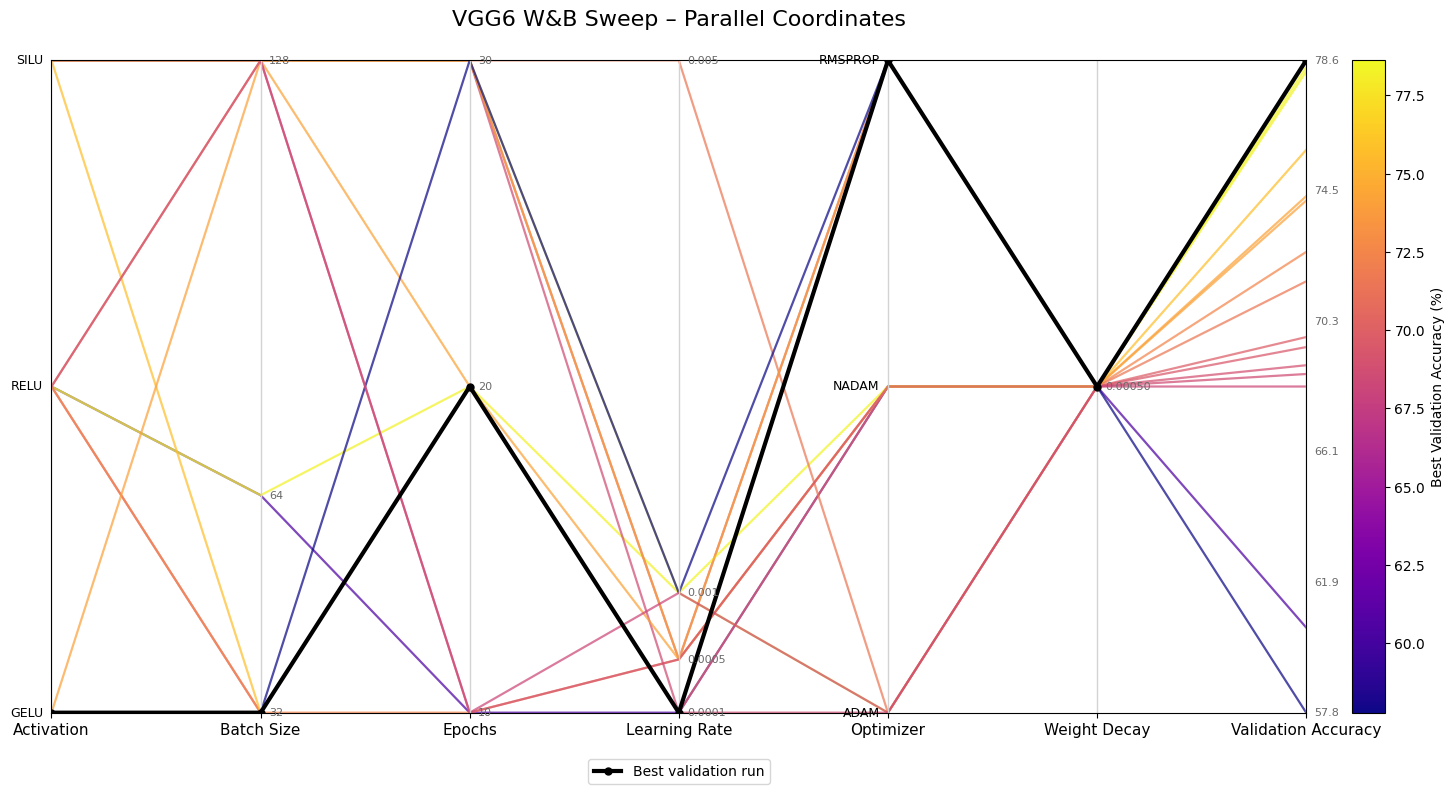

Saved: outputs/q3/wandb_parallel_coordinates_style.png

Best configuration:
activation                     gelu
batch_size                       32
epochs                           20
learning_rate                0.0001
optimizer                   rmsprop
weight_decay                 0.0005
best_validation_accuracy      78.62
Name: 11, dtype: object


In [125]:
#Optimizer + Activation Interaction Plot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from pathlib import Path

# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_columns = [
    "activation",
    "batch_size",
    "epochs",
    "learning_rate",
    "optimizer",
    "weight_decay",
    "best_validation_accuracy",
]

missing = [
    col for col in required_columns
    if col not in q2c_df.columns
]

if missing:
    raise RuntimeError(
        f"Missing columns: {missing}\n"
        f"Available columns: {q2c_df.columns.tolist()}"
    )

df = (
    q2c_df[required_columns]
    .dropna()
    .copy()
)

# ------------------------------------------------------------
# Convert numeric columns
# ------------------------------------------------------------

numeric_columns = [
    "batch_size",
    "epochs",
    "learning_rate",
    "weight_decay",
    "best_validation_accuracy",
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna().reset_index(drop=True)

# ------------------------------------------------------------
# Preserve readable categorical names
# ------------------------------------------------------------

activation_values = sorted(
    df["activation"].astype(str).unique()
)

optimizer_values = sorted(
    df["optimizer"].astype(str).unique()
)

activation_map = {
    name: i
    for i, name in enumerate(activation_values)
}

optimizer_map = {
    name: i
    for i, name in enumerate(optimizer_values)
}

df["activation_code"] = (
    df["activation"]
    .map(activation_map)
)

df["optimizer_code"] = (
    df["optimizer"]
    .map(optimizer_map)
)

# ------------------------------------------------------------
# Dimensions to plot
# ------------------------------------------------------------

dimensions = [
    ("Activation", "activation_code"),
    ("Batch Size", "batch_size"),
    ("Epochs", "epochs"),
    ("Learning Rate", "learning_rate"),
    ("Optimizer", "optimizer_code"),
    ("Weight Decay", "weight_decay"),
    ("Validation Accuracy", "best_validation_accuracy"),
]

# ------------------------------------------------------------
# Convert each independent axis to normalized 0-1 coordinates
# while retaining its original labels
# ------------------------------------------------------------

normalized = pd.DataFrame(index=df.index)

axis_info = {}

for display_name, column in dimensions:

    values = df[column].astype(float)

    min_value = values.min()
    max_value = values.max()

    if max_value == min_value:
        normalized[column] = 0.5
    else:
        normalized[column] = (
            values - min_value
        ) / (
            max_value - min_value
        )

    axis_info[column] = (
        min_value,
        max_value
    )

# ------------------------------------------------------------
# Color lines according to validation accuracy
# ------------------------------------------------------------

accuracy = df[
    "best_validation_accuracy"
]

color_norm = Normalize(
    vmin=accuracy.min(),
    vmax=accuracy.max()
)

cmap = plt.cm.plasma

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, host = plt.subplots(
    figsize=(16, 8)
)

x_positions = np.arange(
    len(dimensions)
)

# Draw every run
for row_index in df.index:

    y_values = [
        normalized.loc[
            row_index,
            column
        ]
        for _, column in dimensions
    ]

    host.plot(
        x_positions,
        y_values,
        color=cmap(
            color_norm(
                df.loc[
                    row_index,
                    "best_validation_accuracy"
                ]
            )
        ),
        linewidth=1.6,
        alpha=0.72
    )

# ------------------------------------------------------------
# Main normalized axis
# ------------------------------------------------------------

host.set_xlim(
    0,
    len(dimensions) - 1
)

host.set_ylim(
    0,
    1
)

host.set_xticks(
    x_positions
)

host.set_xticklabels(
    [
        name
        for name, _ in dimensions
    ],
    fontsize=11
)

host.set_yticks([])

host.set_title(
    "VGG6 W&B Sweep – Parallel Coordinates",
    fontsize=16,
    pad=25
)

# Draw vertical axes
for x in x_positions:
    host.axvline(
        x,
        color="lightgray",
        linewidth=1
    )

# ------------------------------------------------------------
# Helper to map an original numeric value to normalized position
# ------------------------------------------------------------

def normalized_position(
    value,
    minimum,
    maximum
):
    if maximum == minimum:
        return 0.5

    return (
        value - minimum
    ) / (
        maximum - minimum
    )

# ------------------------------------------------------------
# Add categorical labels
# ------------------------------------------------------------

# Activation axis
for name, code in activation_map.items():

    minimum, maximum = axis_info[
        "activation_code"
    ]

    host.text(
        0 - 0.04,
        normalized_position(
            code,
            minimum,
            maximum
        ),
        name.upper(),
        ha="right",
        va="center",
        fontsize=9
    )

# Optimizer axis
optimizer_axis = 4

for name, code in optimizer_map.items():

    minimum, maximum = axis_info[
        "optimizer_code"
    ]

    host.text(
        optimizer_axis - 0.04,
        normalized_position(
            code,
            minimum,
            maximum
        ),
        name.upper(),
        ha="right",
        va="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Numeric axis ticks
# ------------------------------------------------------------

numeric_axis_columns = [
    ("batch_size", 1),
    ("epochs", 2),
    ("learning_rate", 3),
    ("weight_decay", 5),
    ("best_validation_accuracy", 6),
]

for column, axis_index in numeric_axis_columns:

    minimum, maximum = axis_info[
        column
    ]

    unique_values = sorted(
        df[column].unique()
    )

    # Prevent overly crowded axes
    if len(unique_values) > 8:
        tick_values = np.linspace(
            minimum,
            maximum,
            6
        )
    else:
        tick_values = unique_values

    for value in tick_values:

        y = normalized_position(
            value,
            minimum,
            maximum
        )

        if column == "learning_rate":
            label = f"{value:.4g}"

        elif column == "weight_decay":
            label = f"{value:.5f}"

        elif column == "best_validation_accuracy":
            label = f"{value:.1f}"

        else:
            label = f"{value:g}"

        host.text(
            axis_index + 0.04,
            y,
            label,
            ha="left",
            va="center",
            fontsize=8,
            color="dimgray"
        )

# ------------------------------------------------------------
# Accuracy color bar
# ------------------------------------------------------------

scalar_mappable = ScalarMappable(
    norm=color_norm,
    cmap=cmap
)

scalar_mappable.set_array([])

cbar = fig.colorbar(
    scalar_mappable,
    ax=host,
    pad=0.03
)

cbar.set_label(
    "Best Validation Accuracy (%)",
    fontsize=10
)

# ------------------------------------------------------------
# Highlight best run
# ------------------------------------------------------------

best_index = (
    df[
        "best_validation_accuracy"
    ]
    .idxmax()
)

best_y = [
    normalized.loc[
        best_index,
        column
    ]
    for _, column in dimensions
]

host.plot(
    x_positions,
    best_y,
    color="black",
    linewidth=3,
    marker="o",
    markersize=5,
    label="Best validation run"
)

host.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12)
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "outputs/q3"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    OUTPUT_DIR /
    "wandb_parallel_coordinates_style.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    output_file
)

print("\nBest configuration:")

print(
    df.loc[
        best_index,
        required_columns
    ]
)

In [126]:
# ============================================================
# Q3(b) - Validation Accuracy vs Step
# Data extracted directly from W&B
# ============================================================

import wandb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

api = wandb.Api()

# Use your combined-sweep ID
# If COMBINED_SWEEP already exists, no change is required.
Q3_SWEEP = COMBINED_SWEEP

sweep = api.sweep(Q3_SWEEP)

records = []

for run in sweep.runs:

    if run.state != "finished":
        continue

    best_val = run.summary.get(
        "best_validation_accuracy"
    )

    if best_val is None:
        continue

    records.append({
        "run_name":
            run.name,

        "created_at":
            run.created_at,

        "activation":
            run.config.get("activation"),

        "optimizer":
            run.config.get("optimizer"),

        "learning_rate":
            run.config.get("learning_rate"),

        "batch_size":
            run.config.get("batch_size"),

        "epochs":
            run.config.get("epochs"),

        "best_validation_accuracy":
            float(best_val),
    })


if not records:
    raise RuntimeError(
        "No finished W&B runs containing "
        "'best_validation_accuracy' were found."
    )


scatter_df = pd.DataFrame(records)

print(
    f"Extracted {len(scatter_df)} "
    "completed W&B runs."
)

display(scatter_df.head())

Extracted 15 completed W&B runs.


,run_name,created_at,activation,optimizer,learning_rate,batch_size,epochs,best_validation_accuracy
0,flowing-sweep-1,2026-10-30T06:14:38Z,relu,nadam,0.0001,64,10,60.50
1,feasible-sweep-2,2026-10-30T06:16:50Z,relu,adam,0.0010,64,20,78.26
2,comfy-sweep-3,2026-10-30T06:20:48Z,relu,nadam,0.0001,32,20,69.78
3,mild-sweep-4,2026-10-30T06:25:08Z,silu,rmsprop,0.0005,128,30,69.46
4,upbeat-sweep-5,2026-10-30T06:30:53Z,relu,nadam,0.0005,32,10,72.50


In [127]:
# ============================================================
# Prepare data
# ============================================================

scatter_df["created_at"] = pd.to_datetime(
    scatter_df["created_at"],
    utc=True,
    errors="coerce"
)

scatter_df = (
    scatter_df
    .dropna(
        subset=[
            "created_at",
            "best_validation_accuracy"
        ]
    )
    .sort_values(
        "created_at"
    )
    .reset_index(drop=True)
)

# Run order becomes Step
scatter_df["step"] = np.arange(
    1,
    len(scatter_df) + 1
)

# Running best accuracy
scatter_df["running_best_validation_accuracy"] = (
    scatter_df[
        "best_validation_accuracy"
    ]
    .cummax()
)

display(
    scatter_df[
        [
            "step",
            "run_name",
            "activation",
            "optimizer",
            "learning_rate",
            "batch_size",
            "epochs",
            "best_validation_accuracy",
            "running_best_validation_accuracy",
        ]
    ]
)

,step,run_name,activation,optimizer,learning_rate,batch_size,epochs,best_validation_accuracy,running_best_validation_accuracy
0,1,flowing-sweep-1,relu,nadam,0.0001,64,10,60.50,60.50
1,2,feasible-sweep-2,relu,adam,0.0010,64,20,78.26,78.26
2,3,comfy-sweep-3,relu,nadam,0.0001,32,20,69.78,78.26
3,4,mild-sweep-4,silu,rmsprop,0.0005,128,30,69.46,78.26
4,5,upbeat-sweep-5,relu,nadam,0.0005,32,10,72.50,78.26
5,6,ancient-sweep-6,silu,adam,0.0001,128,30,68.60,78.26
6,7,giddy-sweep-7,silu,nadam,0.0005,128,20,74.28,78.26
7,8,fiery-sweep-8,silu,nadam,0.0010,128,30,78.40,78.40
8,9,efficient-sweep-9,relu,adam,0.0050,128,30,71.56,78.40
9,10,bumbling-sweep-10,silu,rmsprop,0.0001,32,20,75.76,78.40


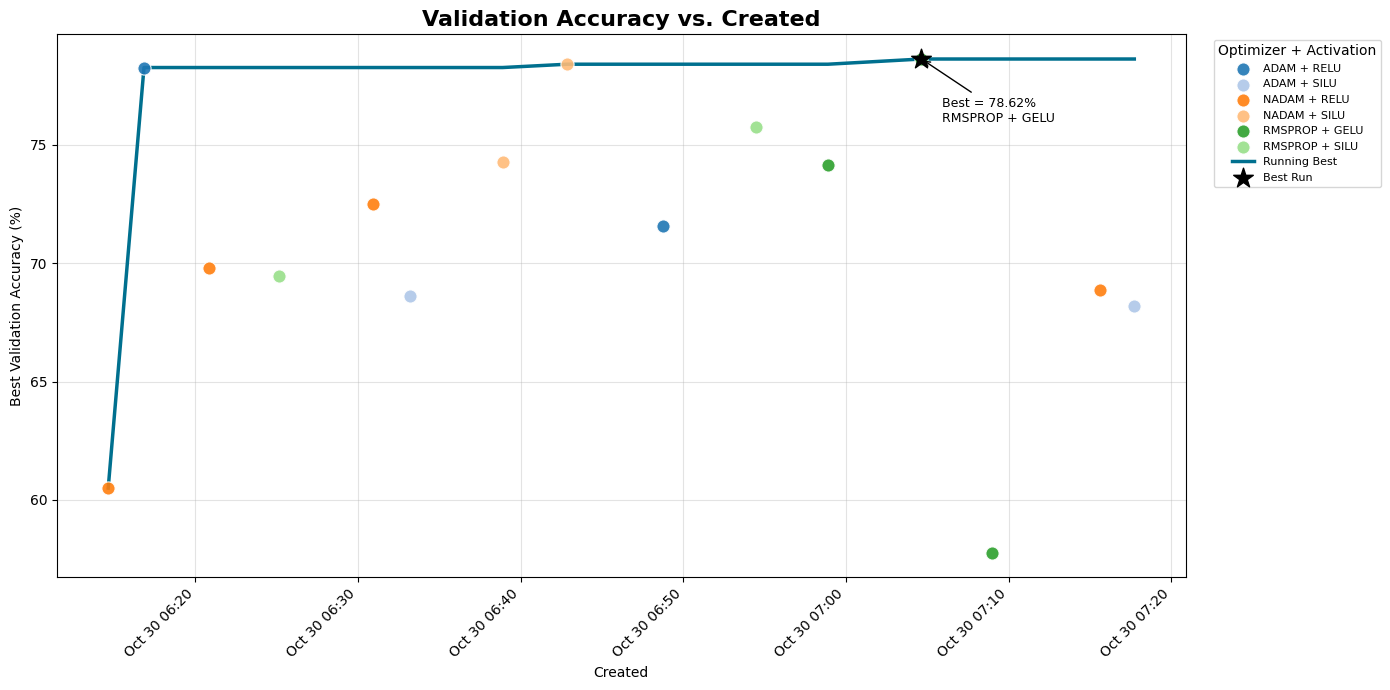

Saved: outputs/q3/validation_accuracy_vs_created_sample_style.png


In [131]:
# ============================================================
# Q3(b) - Validation Accuracy vs Created
# Sample-style date formatting
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

OUTPUT_DIR = Path("outputs/q3")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Ensure chronological order
scatter_df = (
    scatter_df
    .sort_values("created_at")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(
    figsize=(14, 7)
)

# ------------------------------------------------------------
# Scatter points
# ------------------------------------------------------------

for config in configurations:

    temp = scatter_df[
        scatter_df["configuration"] == config
    ]

    ax.scatter(
        temp["created_at"],
        temp["best_validation_accuracy"],
        s=90,
        alpha=0.9,
        color=colour_map[config],
        label=config,
        edgecolors="white",
        linewidth=0.8,
        zorder=3
    )

# ------------------------------------------------------------
# Running-best line
# ------------------------------------------------------------

ax.plot(
    scatter_df["created_at"],
    scatter_df[
        "running_best_validation_accuracy"
    ],
    color="#00708f",
    linewidth=2.5,
    label="Running Best",
    zorder=2
)

# ------------------------------------------------------------
# Highlight overall best run
# ------------------------------------------------------------

best_index = (
    scatter_df[
        "best_validation_accuracy"
    ].idxmax()
)

best_row = scatter_df.loc[
    best_index
]

ax.scatter(
    [best_row["created_at"]],
    [
        best_row[
            "best_validation_accuracy"
        ]
    ],
    s=220,
    marker="*",
    color="black",
    zorder=5,
    label="Best Run"
)

# ------------------------------------------------------------
# Annotate best run
# ------------------------------------------------------------

ax.annotate(
    (
        f"Best = "
        f"{best_row['best_validation_accuracy']:.2f}%\n"
        f"{best_row['optimizer'].upper()} + "
        f"{best_row['activation'].upper()}"
    ),
    xy=(
        best_row["created_at"],
        best_row[
            "best_validation_accuracy"
        ]
    ),
    xytext=(15, -45),
    textcoords="offset points",
    fontsize=9,
    arrowprops={
        "arrowstyle": "->",
        "color": "black"
    }
)

# ------------------------------------------------------------
# DATE FORMAT SIMILAR TO SAMPLE
# ------------------------------------------------------------

date_formatter = mdates.DateFormatter(
    "%b %d %H:%M"
)

ax.xaxis.set_major_formatter(
    date_formatter
)

# Automatically choose sensible time intervals
locator = mdates.AutoDateLocator(
    minticks=6,
    maxticks=12
)

ax.xaxis.set_major_locator(
    locator
)

# Rotate date/time labels similar to sample
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_title(
    "Validation Accuracy vs. Created",
    fontsize=16,
    weight="bold"
)

ax.set_xlabel(
    "Created"
)

ax.set_ylabel(
    "Best Validation Accuracy (%)"
)

ax.grid(
    True,
    alpha=0.35
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    title="Optimizer + Activation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_file = (
    OUTPUT_DIR /
    "validation_accuracy_vs_created_sample_style.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    output_file
)

In [133]:
import wandb
import pandas as pd
from pathlib import Path

api = wandb.Api()

# Reuse the combined sweep already created earlier.
Q3_SWEEP = COMBINED_SWEEP

sweep = api.sweep(Q3_SWEEP)

history_records = []

finished_runs = [
    run
    for run in sweep.runs
    if run.state == "finished"
]

print(
    "Finished runs found:",
    len(finished_runs)
)

for run in finished_runs:

    history = run.history(
        keys=[
            "epoch",
            "train/loss",
            "train/accuracy",
            "validation/loss",
            "validation/accuracy",
        ],
        pandas=True
    )

    if history.empty:
        continue

    activation = str(
        run.config.get(
            "activation",
            "unknown"
        )
    )

    optimizer = str(
        run.config.get(
            "optimizer",
            "unknown"
        )
    )

    learning_rate = run.config.get(
        "learning_rate"
    )

    batch_size = run.config.get(
        "batch_size"
    )

    epochs = run.config.get(
        "epochs"
    )

    # Compact but informative run label
    run_label = (
        f"{optimizer.upper()} + "
        f"{activation.upper()} | "
        f"lr={learning_rate} | "
        f"bs={batch_size} | "
        f"ep={epochs}"
    )

    for _, row in history.iterrows():

        history_records.append({

            "run_name":
                run.name,

            "run_label":
                run_label,

            "activation":
                activation,

            "optimizer":
                optimizer,

            "learning_rate":
                learning_rate,

            "batch_size":
                batch_size,

            "epochs_config":
                epochs,

            "epoch":
                row.get("epoch"),

            "train_loss":
                row.get(
                    "train/loss"
                ),

            "train_accuracy":
                row.get(
                    "train/accuracy"
                ),

            "validation_loss":
                row.get(
                    "validation/loss"
                ),

            "validation_accuracy":
                row.get(
                    "validation/accuracy"
                ),
        })


history_df = pd.DataFrame(
    history_records
)

if history_df.empty:

    raise RuntimeError(
        "No W&B metric histories were retrieved."
    )


numeric_columns = [
    "epoch",
    "train_loss",
    "train_accuracy",
    "validation_loss",
    "validation_accuracy",
]

for column in numeric_columns:

    history_df[column] = pd.to_numeric(
        history_df[column],
        errors="coerce"
    )


OUTPUT_DIR = Path(
    "outputs/q3"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


history_df.to_csv(
    OUTPUT_DIR /
    "q3_wandb_history.csv",
    index=False
)


print(
    "History rows extracted:",
    len(history_df)
)

print(
    "Runs represented:",
    history_df[
        "run_name"
    ].nunique()
)

display(
    history_df.head()
)

Finished runs found: 15
History rows extracted: 320
Runs represented: 15


,run_name,run_label,activation,optimizer,learning_rate,batch_size,epochs_config,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,flowing-sweep-1,NADAM + RELU | lr=0.0001 | bs=64 | ep=10,relu,nadam,0.0001,64,10,1.0,1.761154,36.717778,1.514780,45.42
1,flowing-sweep-1,NADAM + RELU | lr=0.0001 | bs=64 | ep=10,relu,nadam,0.0001,64,10,2.0,1.504399,46.602222,1.425237,50.78
2,flowing-sweep-1,NADAM + RELU | lr=0.0001 | bs=64 | ep=10,relu,nadam,0.0001,64,10,3.0,1.407459,50.011111,1.350137,51.54
3,flowing-sweep-1,NADAM + RELU | lr=0.0001 | bs=64 | ep=10,relu,nadam,0.0001,64,10,4.0,1.347946,52.124444,1.302338,53.54
4,flowing-sweep-1,NADAM + RELU | lr=0.0001 | bs=64 | ep=10,relu,nadam,0.0001,64,10,5.0,1.300473,54.133333,1.332544,54.16


In [134]:
metrics = [
    "train_accuracy",
    "train_loss",
    "validation_accuracy",
    "validation_loss",
]


for metric in metrics:

    available_values = (
        history_df[
            metric
        ].notna().sum()
    )

    print(
        f"{metric:25}: "
        f"{available_values} values"
    )


train_accuracy           : 320 values
train_loss               : 320 values
validation_accuracy      : 320 values
validation_loss          : 320 values


In [135]:
import matplotlib.pyplot as plt


def plot_wandb_metric(
    dataframe,
    metric,
    title,
    ylabel,
    output_file
):

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    run_labels = (
        dataframe[
            "run_label"
        ]
        .dropna()
        .unique()
    )

    colors = plt.cm.tab20(
        range(
            len(run_labels)
        )
    )

    color_map = dict(
        zip(
            run_labels,
            colors
        )
    )

    for run_label in run_labels:

        temp = (
            dataframe[
                dataframe[
                    "run_label"
                ] == run_label
            ]
            .dropna(
                subset=[
                    "epoch",
                    metric
                ]
            )
            .sort_values(
                "epoch"
            )
        )

        if temp.empty:
            continue

        ax.plot(
            temp["epoch"],
            temp[metric],
            linewidth=2,
            alpha=0.85,
            color=color_map[
                run_label
            ],
            label=run_label
        )

        # Final point marker, similar to W&B
        ax.scatter(
            temp["epoch"].iloc[-1],
            temp[metric].iloc[-1],
            s=45,
            color=color_map[
                run_label
            ],
            zorder=4
        )


    ax.set_title(
        title,
        fontsize=16,
        weight="bold"
    )

    ax.set_xlabel(
        "Step / Epoch",
        fontsize=11
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        title="Configuration",
        bbox_to_anchor=(
            1.02,
            1
        ),
        loc="upper left",
        fontsize=7
    )

    plt.tight_layout()

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "Saved:",
        output_file
    )

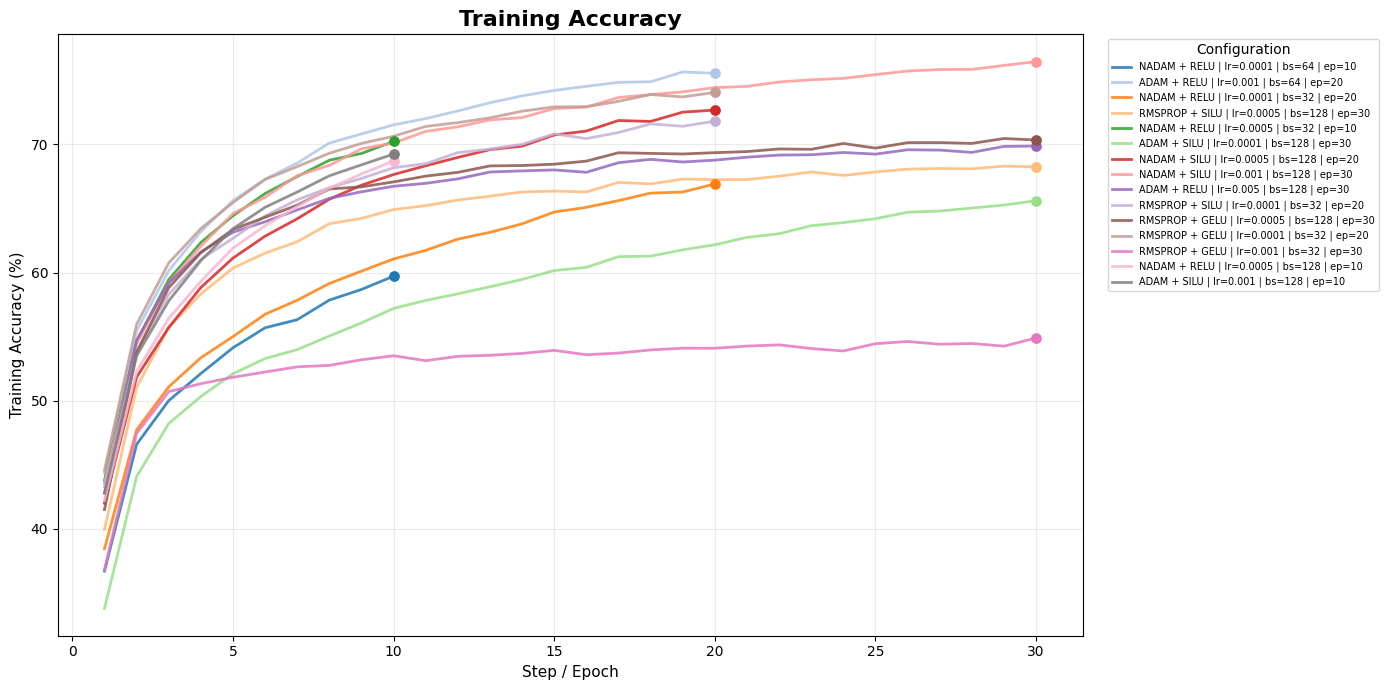

Saved: outputs/q3/training_accuracy.png


In [136]:
plot_wandb_metric(
    dataframe=history_df,

    metric="train_accuracy",

    title="Training Accuracy",

    ylabel="Training Accuracy (%)",

    output_file=(
        OUTPUT_DIR /
        "training_accuracy.png"
    )
)

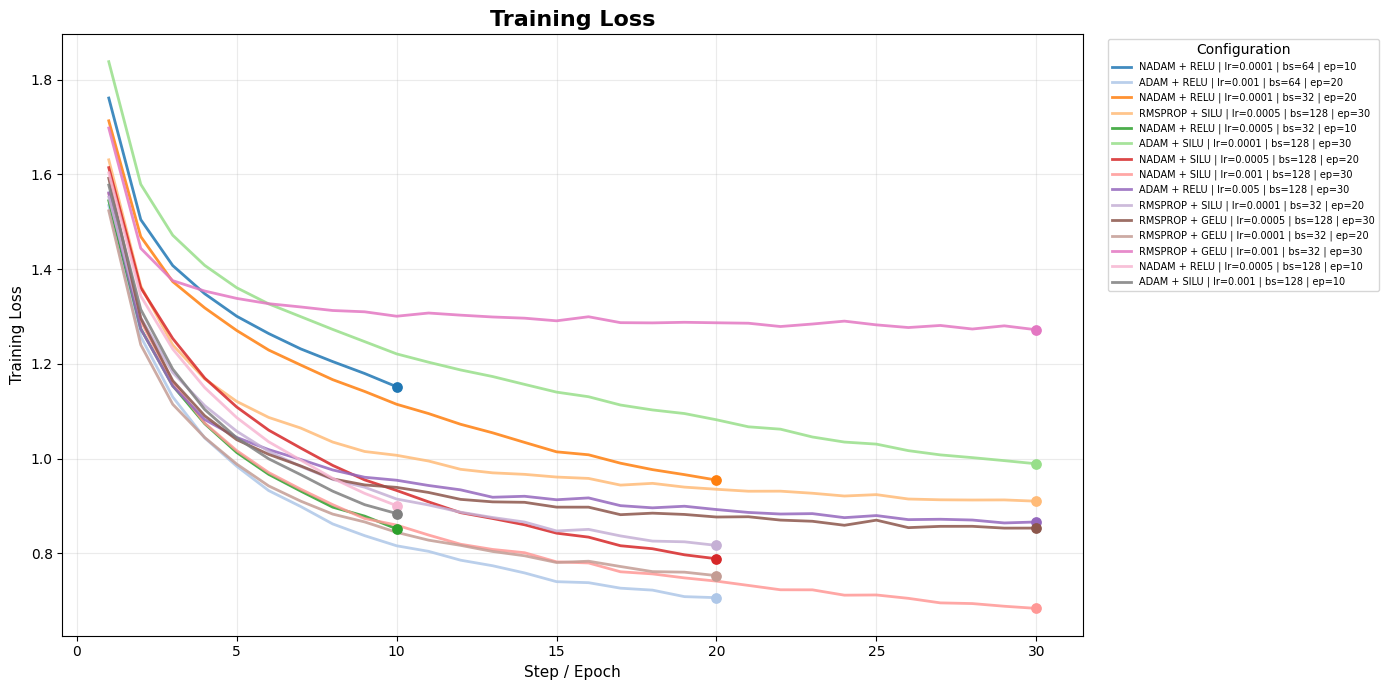

Saved: outputs/q3/training_loss.png


In [138]:
plot_wandb_metric(
    dataframe=history_df,

    metric="train_loss",

    title="Training Loss",

    ylabel="Training Loss",

    output_file=(
        OUTPUT_DIR /
        "training_loss.png"
    )
)

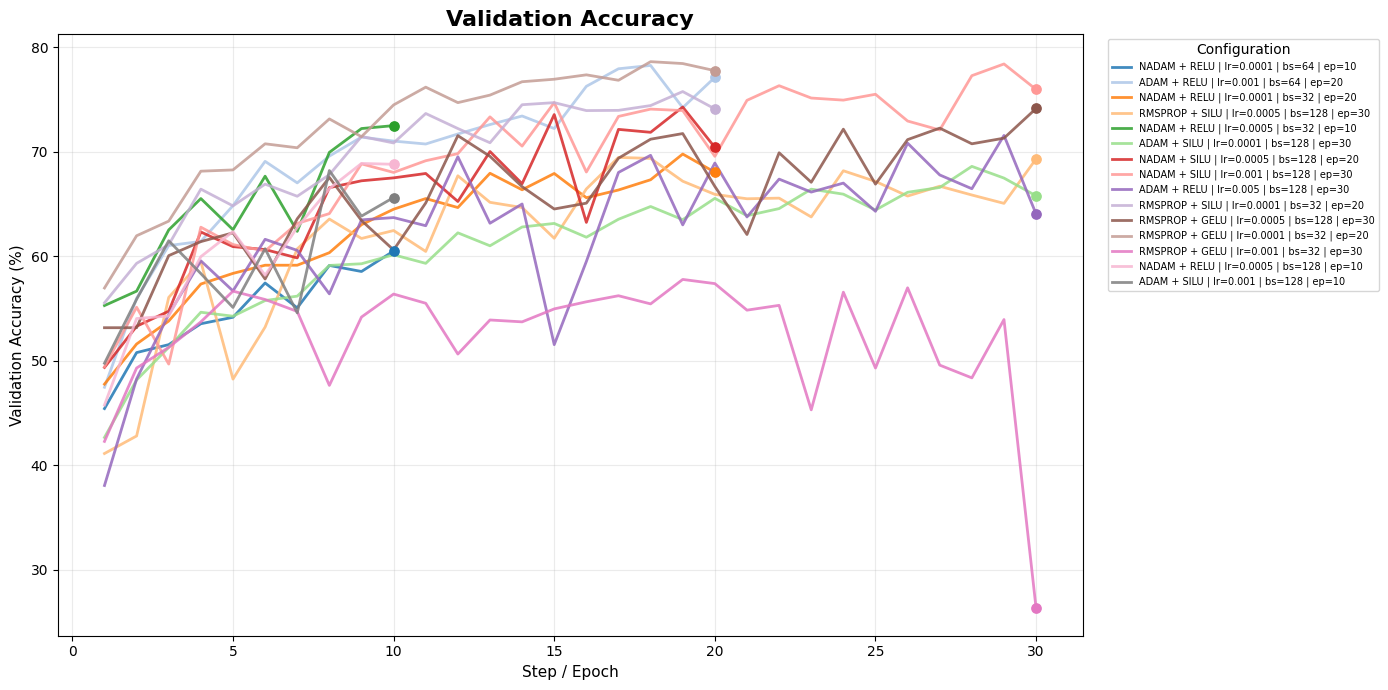

Saved: outputs/q3/validation_accuracy.png


In [139]:
plot_wandb_metric(
    dataframe=history_df,

    metric="validation_accuracy",

    title="Validation Accuracy",

    ylabel="Validation Accuracy (%)",

    output_file=(
        OUTPUT_DIR /
        "validation_accuracy.png"
    )
)

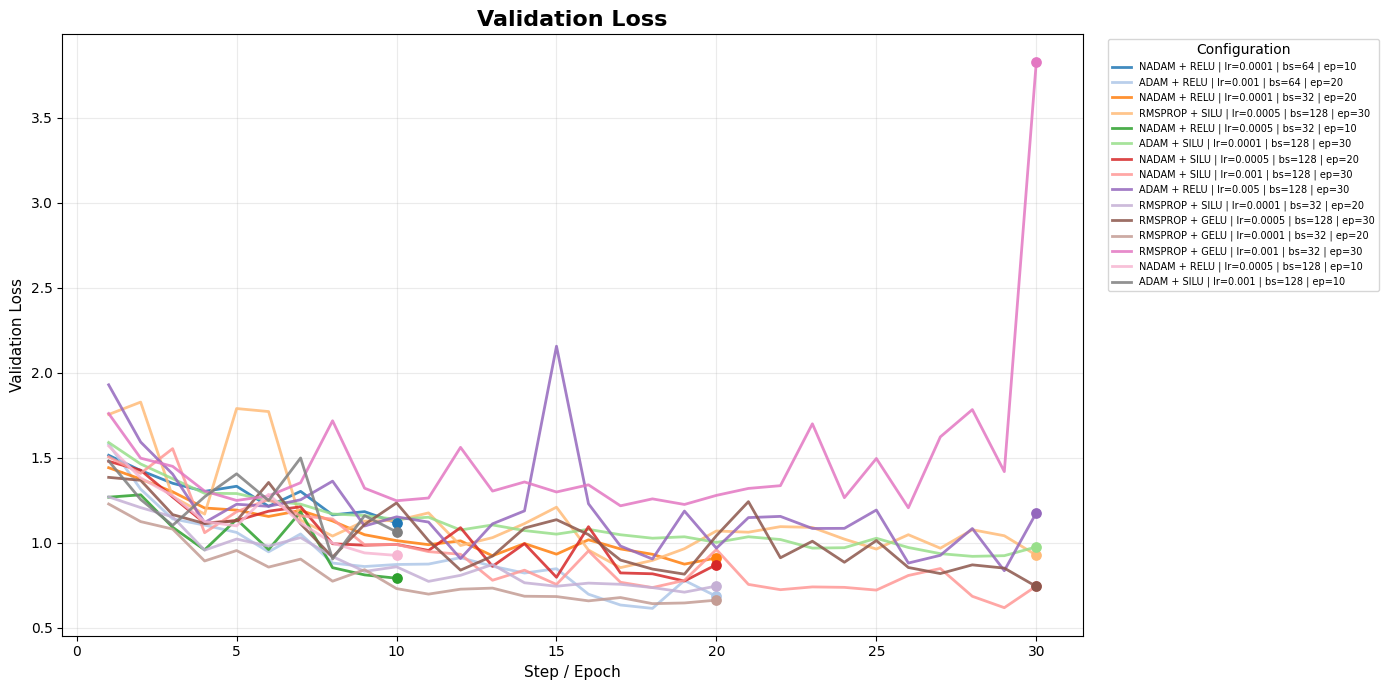

Saved: outputs/q3/validation_loss.png


In [140]:
plot_wandb_metric(
    dataframe=history_df,

    metric="validation_loss",

    title="Validation Loss",

    ylabel="Validation Loss",

    output_file=(
        OUTPUT_DIR /
        "validation_loss.png"
    )
)

In [142]:
%cd /content/vgg6_workspace/VGG6-CIFAR10

/content/vgg6_workspace/VGG6-CIFAR10


In [143]:
!pwd
!ls configs

/content/vgg6_workspace/VGG6-CIFAR10
activation_sweep.yaml  best.yaml	    optimizer_sweep.yaml
baseline.yaml	       combined_sweep.yaml


In [144]:
%%writefile configs/best.yaml
activation: gelu
optimizer: rmsprop
learning_rate: 0.0001
batch_size: 32
epochs: 20
weight_decay: 0.0005
seed: 42
workers: 2
data_dir: data

use_wandb: true
wandb_project: vgg6-cifar10

checkpoint_path: checkpoints/best_model.pt
history_path: outputs/best_history.csv

Overwriting configs/best.yaml


In [145]:
from pathlib import Path

print(
    Path("configs/best.yaml").read_text()
)

activation: gelu
optimizer: rmsprop
learning_rate: 0.0001
batch_size: 32
epochs: 20
weight_decay: 0.0005
seed: 42
workers: 2
data_dir: data

use_wandb: true
wandb_project: vgg6-cifar10

checkpoint_path: checkpoints/best_model.pt
history_path: outputs/best_history.csv



In [146]:
import yaml

with open(
    "configs/best.yaml",
    "r"
) as file:

    best_config = yaml.safe_load(file)

print(best_config)

{'activation': 'gelu', 'optimizer': 'rmsprop', 'learning_rate': 0.0001, 'batch_size': 32, 'epochs': 20, 'weight_decay': 0.0005, 'seed': 42, 'workers': 2, 'data_dir': 'data', 'use_wandb': True, 'wandb_project': 'vgg6-cifar10', 'checkpoint_path': 'checkpoints/best_model.pt', 'history_path': 'outputs/best_history.csv'}


In [147]:
assert best_config["activation"] == "gelu"
assert best_config["optimizer"] == "rmsprop"
assert best_config["learning_rate"] == 0.0001
assert best_config["batch_size"] == 32
assert best_config["epochs"] == 20
assert best_config["weight_decay"] == 0.0005
assert best_config["seed"] == 42

print(
    "SUCCESS: best.yaml is valid and "
    "matches the selected configuration."
)

SUCCESS: best.yaml is valid and matches the selected configuration.


In [148]:
!python -m compileall -q src scripts tests

In [149]:
from src.train import train
from src.evaluate import evaluate_checkpoint

print("Imports successful.")

Imports successful.


In [150]:
!python -m src.train \
    --config configs/best.yaml

Device: cuda
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: cs25m537 (cs25m537-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 1r87fihk (0.3s)
wandb: ⣯ setting up run 1r87fihk (0.3s)
wandb: ⣟ setting up run 1r87fihk (0.3s)
wandb: ⡿ setting up run 1r87fihk (0.3s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /content/vgg6_workspace/VGG6-CIFAR10/wandb/run-20261030_113015-1r87fihk
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run forsaken-rift-4
wandb: ⭐️ View project at https://wandb.ai/cs25m537-indian-institute-of-technology-madras/vgg6-cifar10
wandb: 🚀 View run at https://wa

In [151]:
from pathlib import Path

files = [
    "checkpoints/best_model.pt",
    "outputs/best_history.csv",
]

for file in files:

    print(
        file,
        "->",
        "FOUND"
        if Path(file).exists()
        else "MISSING"
    )

checkpoints/best_model.pt -> FOUND
outputs/best_history.csv -> FOUND


In [152]:
!python -m src.evaluate \
    --config configs/best.yaml \
    --checkpoint checkpoints/best_model.pt \
    --split both

{'validation': {'loss': 0.6420137705802917, 'accuracy': 78.62}, 'test': {'loss': 0.6617465424537659, 'accuracy': 77.45}}
